# Run regrid operation on CMIP6

Version: 2026.01.07

**Rooki** calls climate data operations on the **rook** processing service.

In [1]:
import os
os.environ['ROOK_URL'] = 'http://rook.dkrz.de/wps'

from rooki import rooki
from rooki import operators as ops

## Parameters of regrid operation

In [2]:
rooki.regrid?

Signature:
rooki.regrid(
    collection,
    method='nearest_s2d',
    grid='auto',
    custom_grid=None,
)
Docstring:
Run regridding operator on climate model data using daops (xarray).

Parameters
----------
collection : string
    A dataset identifier or list of comma separated identifiers. Example: c3s-cmip5.output1.ICHEC.EC-EARTH.historical.day.atmos.day.r1i1p1.tas.latest
method : {'nearest_s2d', 'bilinear', 'conservative', 'patch'}string
    Please specify regridding method like consevative or bilinear. Default: nearest_s2d
grid : {'auto', '0pt25deg', '0pt25deg_era5', '0pt5deg_lsm', '0pt625x0pt5deg', '0pt75deg', '1deg', '1pt25deg', '2pt5deg', 'custom'}string
    Select target grid resolution for regridding. Choose a predefined grid or select 'custom' to provide your own.
custom_grid : string
    Only used if grid='custom'. Provide space-separated numbers defining the target grid. Allowed lengths: 1 (d), 2 (d_lon d_lat), 3 (lonlat_0 lonlat_1 d_lonlat), 6 (lon_0 lon_1 d_lon lat_0 l

## workflow: subset only

In [3]:
tas = ops.Input(
    'tas', ['c3s-cmip6.CMIP.CNRM-CERFACS.CNRM-CM6-1.historical.r1i1p1f2.Amon.tas.gr.v20180917']
)

wf = ops.Subset(tas, time="2000-01/2000-01")

In [4]:
resp = wf.orchestrate()
resp.ok 

True

In [5]:
ds = resp.datasets()[0]
ds

<xarray.Dataset> Size: 134kB
Dimensions:      (time: 1, axis_nbounds: 2, lat: 128, lon: 256)
Coordinates:
  * time         (time) datetime64[ns] 8B 2000-01-16T12:00:00
  * lat          (lat) float64 1kB -88.93 -87.54 -86.14 ... 86.14 87.54 88.93
  * lon          (lon) float64 2kB 0.0 1.406 2.812 4.219 ... 355.8 357.2 358.6
    height       float64 8B ...
Dimensions without coordinates: axis_nbounds
Data variables:
    time_bounds  (time, axis_nbounds) datetime64[ns] 16B ...
    tas          (time, lat, lon) float32 131kB ...
Attributes: (12/54)
    name:                   /scratch/work/voldoire/outputs/CMIP6/DECK/CNRM-CM...
    Conventions:            CF-1.7 CMIP-6.2
    creation_date:          2018-06-20T08:40:07Z
    description:            CMIP6 historical
    title:                  CNRM-CM6-1 model output prepared for CMIP6 / CMIP...
    activity_id:            CMIP
    ...                     ...
    xios_commit:            1442-shuffle
    nemo_gelato_commit:     49095b3accd5d4c_6524fe19b00467a
    arpege_minor_version:   6.3.2
    tracking_id:            hdl:21.14100/87bf0ea8-e604-4581-b49d-0f98831346b1
    history:                Mon Jul 30 11:58:29 2018: ncatted -O -a tracking_...
    NCO:                    "4.5.5"

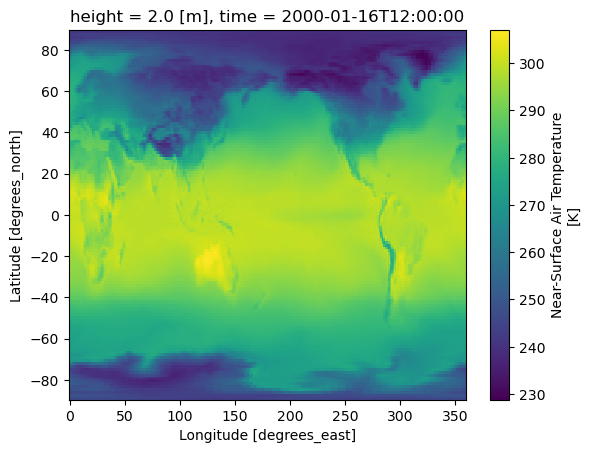

In [6]:
ds.tas.isel(time=0).plot()

## workflow: subset + regrid


In [7]:
tas = ops.Input(
    'tas', ['c3s-cmip6.CMIP.CNRM-CERFACS.CNRM-CM6-1.historical.r1i1p1f2.Amon.tas.gr.v20180917']
)

wf = ops.Subset(tas, time="2000-01/2000-01")

wf = ops.Regrid(wf, method="nearest_s2d", grid="1deg")

In [8]:
resp = wf.orchestrate()
resp.ok 

True

In [9]:
ds = resp.datasets()[0]
ds

<xarray.Dataset> Size: 272kB
Dimensions:      (time: 1, lat: 180, lon: 360, bnds: 2, axis_nbounds: 2)
Coordinates:
  * time         (time) datetime64[ns] 8B 2000-01-16T12:00:00
  * lat          (lat) float64 1kB -89.5 -88.5 -87.5 -86.5 ... 87.5 88.5 89.5
  * lon          (lon) float64 3kB 0.5 1.5 2.5 3.5 ... 356.5 357.5 358.5 359.5
    lat_bnds     (lat, bnds) float64 3kB ...
    lon_bnds     (lon, bnds) float64 6kB ...
    height       float64 8B ...
    time_bounds  (time, axis_nbounds) datetime64[ns] 16B ...
Dimensions without coordinates: bnds, axis_nbounds
Data variables:
    tas          (time, lat, lon) float32 259kB ...
Attributes: (12/59)
    name:                         /scratch/work/voldoire/outputs/CMIP6/DECK/C...
    Conventions:                  CF-1.7 CMIP-6.2
    creation_date:                2018-06-20T08:40:07Z
    description:                  CMIP6 historical
    title:                        CNRM-CM6-1 model output prepared for CMIP6 ...
    activity_id:                  CMIP
    ...                           ...
    grid_original:                data regridded to a T127 gaussian grid (128...
    grid_label_original:          gr
    nominal_resolution_original:  250 km
    regrid_operation:             nearest_s2d_128x256_180x360_peri
    regrid_tool:                  xESMF_v0.8.8
    regrid_weights_uid:           90229ccc58a26ce268bc1fc5d0f7414a_d24f4f689f...

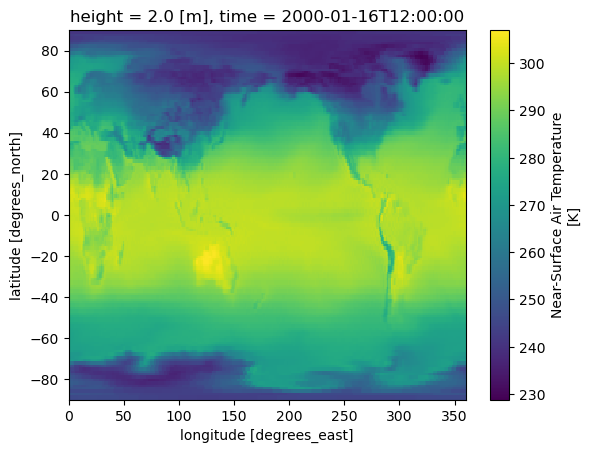

In [10]:
ds.tas.isel(time=0).plot()

## workflow: subset + regrid with custom_grid


In [11]:
tas = ops.Input(
    'tas', ['c3s-cmip6.CMIP.CNRM-CERFACS.CNRM-CM6-1.historical.r1i1p1f2.Amon.tas.gr.v20180917']
)

wf = ops.Subset(tas, time="2000-01/2000-01")

wf = ops.Regrid(wf, method="nearest_s2d", grid="custom", custom_grid="0.5")

In [12]:
resp = wf.orchestrate()
resp.ok 

True

In [13]:
ds = resp.datasets()[0]
ds

<xarray.Dataset> Size: 1MB
Dimensions:      (time: 1, lat: 360, lon: 720, bnds: 2, axis_nbounds: 2)
Coordinates:
  * time         (time) datetime64[ns] 8B 2000-01-16T12:00:00
  * lat          (lat) float64 3kB -89.75 -89.25 -88.75 ... 88.75 89.25 89.75
  * lon          (lon) float64 6kB -179.8 -179.2 -178.8 ... 178.8 179.2 179.8
    lat_bnds     (lat, bnds) float64 6kB ...
    lon_bnds     (lon, bnds) float64 12kB ...
    height       float64 8B ...
    time_bounds  (time, axis_nbounds) datetime64[ns] 16B ...
Dimensions without coordinates: bnds, axis_nbounds
Data variables:
    tas          (time, lat, lon) float32 1MB ...
Attributes: (12/59)
    name:                         /scratch/work/voldoire/outputs/CMIP6/DECK/C...
    Conventions:                  CF-1.7 CMIP-6.2
    creation_date:                2018-06-20T08:40:07Z
    description:                  CMIP6 historical
    title:                        CNRM-CM6-1 model output prepared for CMIP6 ...
    activity_id:                  CMIP
    ...                           ...
    grid_original:                data regridded to a T127 gaussian grid (128...
    grid_label_original:          gr
    nominal_resolution_original:  250 km
    regrid_operation:             nearest_s2d_128x256_360x720_peri
    regrid_tool:                  xESMF_v0.9.2
    regrid_weights_uid:           90229ccc58a26ce268bc1fc5d0f7414a_cd9e54c843...

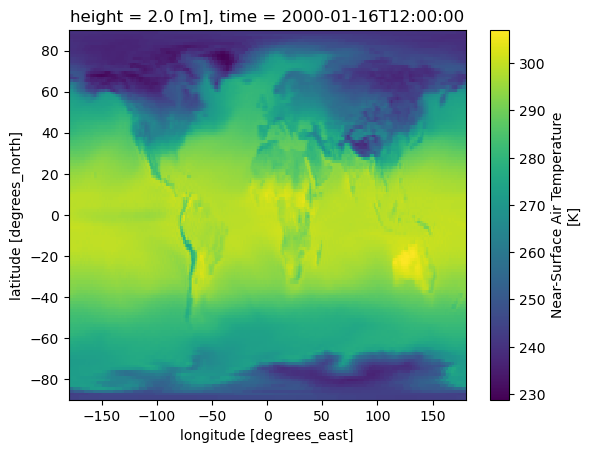

In [14]:
ds.tas.isel(time=0).plot()

## Regridding method comparison

D.2.1.10 lists four methods: `nearest_s2d`, `bilinear`, `conservative`, and `patch`. D.2.1.11 documents robustness improvements for CORDEX data without adding methods. This first comparison holds the CMIP6 input, January 2000 time subset, and `1deg` target grid constant so only the method changes. The existing custom-grid example above remains a separate test.

The deliverable also lists predefined target grids `auto`, `0pt25deg`, `0pt25deg_era5`, `0pt5deg_lsm`, `0pt625x0pt5deg`, `0pt75deg`, `1deg`, `1pt25deg`, and `2pt5deg`. Those grid choices, followed by CORDEX-specific bounds, longitude-frame, and unmapped-cell cases from D.2.1.11, are follow-up tests.

In [3]:
regrid_methods = ["nearest_s2d", "bilinear", "conservative", "patch"]
regrid_method_results = {}

for method in regrid_methods:
    workflow = ops.Regrid(
        ops.Subset(
            ops.Input(
                "tas",
                ["c3s-cmip6.CMIP.CNRM-CERFACS.CNRM-CM6-1.historical.r1i1p1f2.Amon.tas.gr.v20180917"],
            ),
            time="2000-01/2000-01",
        ),
        method=method,
        grid="1deg",
    )
    response = workflow.orchestrate()
    if not response.ok:
        raise RuntimeError(f"Regrid failed for method={method}")
    result = response.datasets()[0]
    regrid_method_results[method] = result
    print(f"{method}: shape={result.tas.shape}, dims={result.tas.dims}")

nearest_s2d: shape=(1, 180, 360), dims=('time', 'lat', 'lon')


bilinear: shape=(1, 180, 360), dims=('time', 'lat', 'lon')


conservative: shape=(1, 180, 360), dims=('time', 'lat', 'lon')


patch: shape=(1, 180, 360), dims=('time', 'lat', 'lon')


## Pairwise differences between methods

For each method pair, the difference is calculated as the first method minus the second. Coordinates must match exactly; statistics use only non-missing values. The table reports signed mean difference, mean absolute difference, RMSE, and maximum absolute difference. The maps use a shared symmetric color scale.

For the `tas` run above, all difference statistics and map color bars are in K.

,valid_cells,mean_difference,mean_absolute_difference,rmse,maximum_absolute_difference
comparison,,,,,
nearest_s2d - bilinear,64800,-0.025268,0.415424,0.797878,12.295212
nearest_s2d - conservative,64800,-0.027444,0.311075,0.679598,11.177811
nearest_s2d - patch,64800,-0.024719,0.430241,0.809963,12.071625
bilinear - conservative,64800,-0.002176,0.120720,0.235657,5.321686
bilinear - patch,64800,0.000549,0.045478,0.100776,2.516296
conservative - patch,64800,0.002725,0.142923,0.272188,5.712585


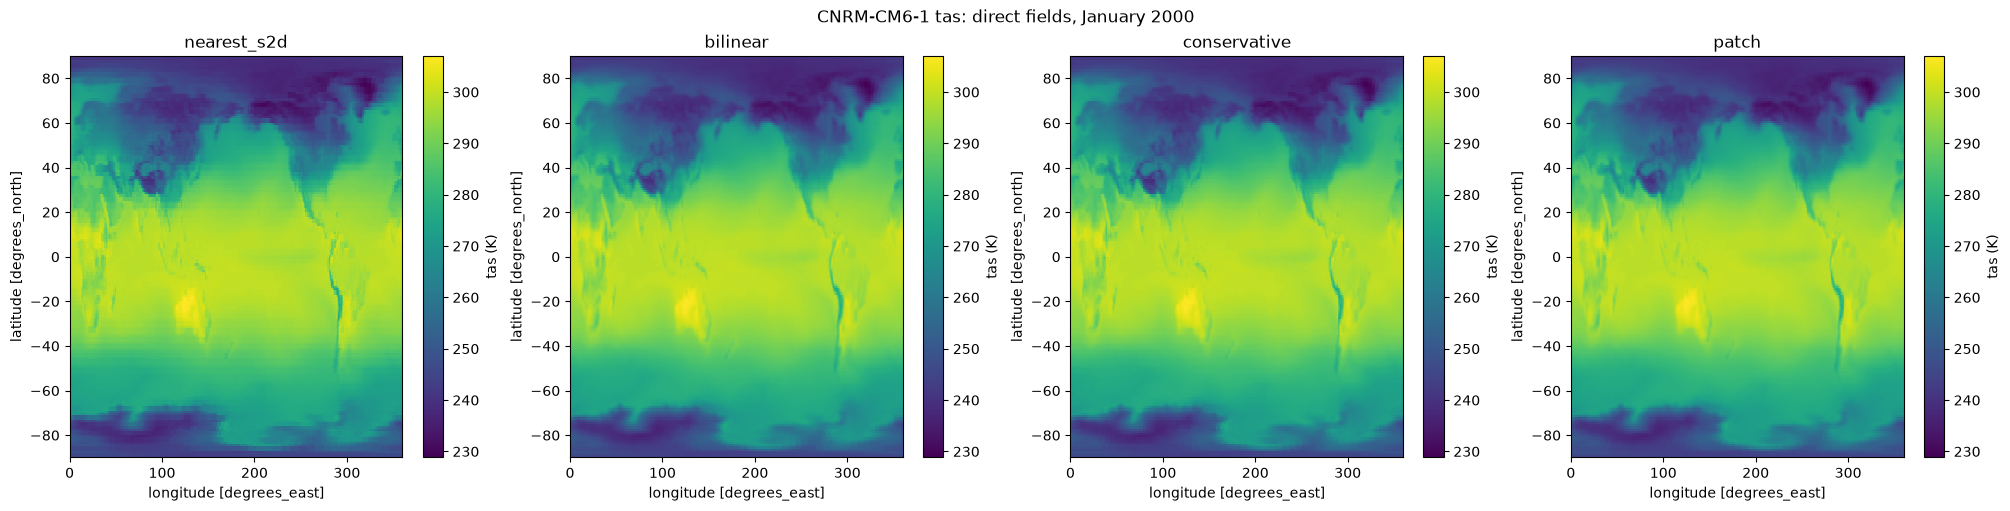

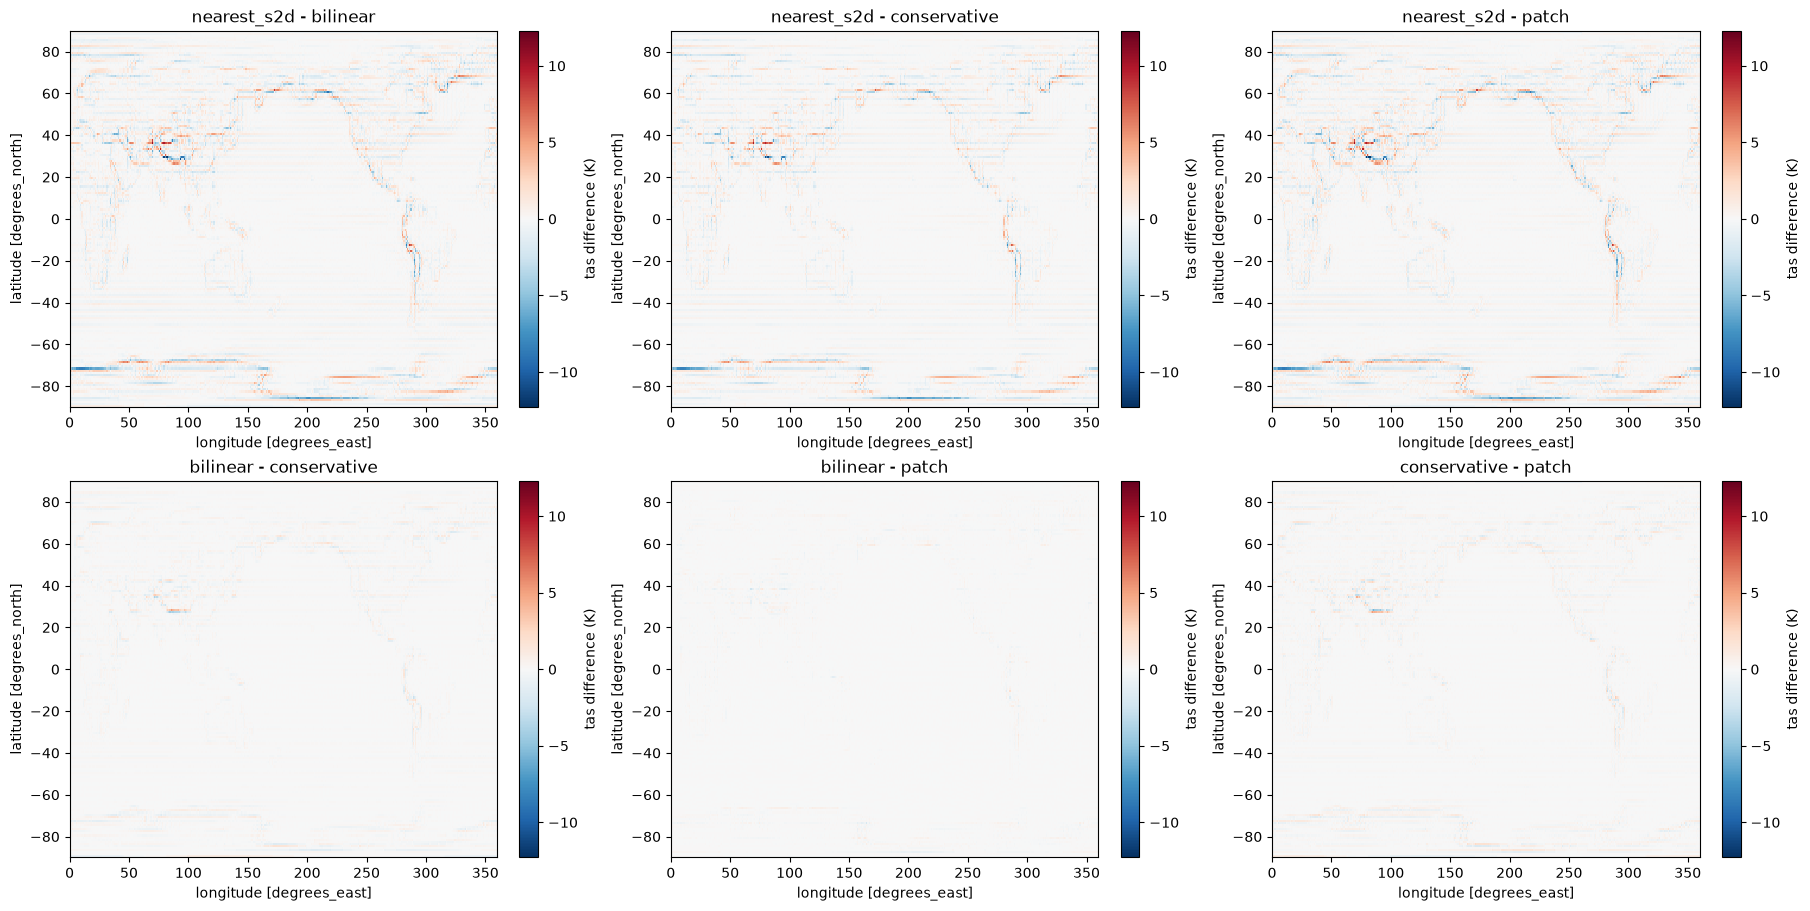

In [7]:
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr

difference_fields = {}
difference_rows = []

for method_a, method_b in combinations(regrid_methods, 2):
    field_a, field_b = xr.align(
        regrid_method_results[method_a]["tas"],
        regrid_method_results[method_b]["tas"],
        join="exact",
    )
    units_a = field_a.attrs.get("units", "")
    units_b = field_b.attrs.get("units", "")
    if units_a != units_b:
        raise ValueError(f"Unit mismatch: {method_a}={units_a!r}, {method_b}={units_b!r}")
    difference = field_a - field_b
    valid_cells = int(difference.count().item())
    if valid_cells == 0:
        raise ValueError(f"No valid overlapping cells for {method_a} - {method_b}")
    label = f"{method_a} - {method_b}"
    difference_fields[label] = difference
    difference_rows.append(
        {
            "comparison": label,
            "valid_cells": valid_cells,
            "mean_difference": float(difference.mean(skipna=True).item()),
            "mean_absolute_difference": float(abs(difference).mean(skipna=True).item()),
            "rmse": float(np.sqrt((difference**2).mean(skipna=True)).item()),
            "maximum_absolute_difference": float(abs(difference).max(skipna=True).item()),
        }
    )

difference_summary = pd.DataFrame(difference_rows).set_index("comparison")
from IPython.display import display
display(difference_summary)

fields = [regrid_method_results[method]['tas'].isel(time=0) for method in regrid_methods]
field_min = min(float(field.min().item()) for field in fields)
field_max = max(float(field.max().item()) for field in fields)
figure, axes = plt.subplots(1, 4, figsize=(20, 5), constrained_layout=True)
for axis, method, field in zip(axes, regrid_methods, fields):
    axis.set_facecolor('lightgrey')
    field.plot(ax=axis, vmin=field_min, vmax=field_max,
               cbar_kwargs={'label': f'tas ({field.attrs.get("units")})'})
    axis.set_title(method)
figure.suptitle('CNRM-CM6-1 tas: direct fields, January 2000')
plt.show()

max_abs_difference = difference_summary["maximum_absolute_difference"].max()
color_limit = max(float(max_abs_difference), np.finfo(float).eps)
units = regrid_method_results[regrid_methods[0]]["tas"].attrs.get("units", "source units")
figure, axes = plt.subplots(2, 3, figsize=(18, 9), constrained_layout=True)
for axis, (label, difference) in zip(axes.flat, difference_fields.items()):
    difference.isel(time=0).plot(
        ax=axis,
        cmap="RdBu_r",
        vmin=-color_limit,
        vmax=color_limit,
        cbar_kwargs={"label": f"tas difference ({units})"},
    )
    axis.set_title(label)
plt.show()

## Additional model and variable tests

To check whether the method behavior is specific to the CNRM atmospheric `tas` example, the same four methods and `1deg` target are applied to MIROC `tas`, SAM0-UNICON daily `pr`, and NorESM2-MM ocean `tos`. Each request uses a short period. The cells below also retain partial results if a later method fails, so the other model tests can still be run.

In [3]:
additional_regrid_cases = {}

def test_regrid_case(case_name, variable, dataset_id, time_range, grid="1deg"):
    case = {
        "variable": variable,
        "dataset_id": dataset_id,
        "time_range": time_range,
        "results": {},
    }
    additional_regrid_cases[case_name] = case
    for method in regrid_methods:
        print(f"Running {case_name}: {method}")
        workflow = ops.Regrid(
            ops.Subset(
                ops.Input(variable, [dataset_id]),
                time=time_range,
            ),
            method=method,
            grid=grid,
        )
        response = workflow.orchestrate()
        if not response.ok:
            raise RuntimeError(f"Regrid failed for {case_name}, method={method}")
        result = response.datasets()[0]
        case["results"][method] = result
        print(f"  shape={result[variable].shape}, dims={result[variable].dims}")
    return case["results"]

In [4]:
miroc_tas_results = test_regrid_case(
    "MIROC-ES2H tas",
    "tas",
    "c3s-cmip6.CMIP.MIROC.MIROC-ES2H.historical.r1i1p4f2.Amon.tas.gn.v20220322",
    "2000-01/2000-01",
)

Running MIROC-ES2H tas: nearest_s2d


  shape=(1, 180, 360), dims=('time', 'lat', 'lon')
Running MIROC-ES2H tas: bilinear


  shape=(1, 180, 360), dims=('time', 'lat', 'lon')
Running MIROC-ES2H tas: conservative


  shape=(1, 180, 360), dims=('time', 'lat', 'lon')
Running MIROC-ES2H tas: patch


  shape=(1, 180, 360), dims=('time', 'lat', 'lon')


In [5]:
sam0_pr_results = test_regrid_case(
    "SAM0-UNICON pr",
    "pr",
    "c3s-cmip6.CMIP.SNU.SAM0-UNICON.historical.r1i1p1f1.day.pr.gn.v20190323",
    "1850-01-01/1850-01-01",
)

Running SAM0-UNICON pr: nearest_s2d


  shape=(1, 180, 360), dims=('time', 'lat', 'lon')
Running SAM0-UNICON pr: bilinear


  shape=(1, 180, 360), dims=('time', 'lat', 'lon')
Running SAM0-UNICON pr: conservative


  shape=(1, 180, 360), dims=('time', 'lat', 'lon')
Running SAM0-UNICON pr: patch


  shape=(1, 180, 360), dims=('time', 'lat', 'lon')


In [6]:
noresm_tos_results = test_regrid_case(
    "NorESM2-MM tos",
    "tos",
    "c3s-cmip6.ScenarioMIP.NCC.NorESM2-MM.ssp245.r1i1p1f1.Omon.tos.gn.v20191108",
    "2050-04/2050-04",
)

Running NorESM2-MM tos: nearest_s2d


  shape=(1, 180, 360), dims=('time', 'lat', 'lon')
Running NorESM2-MM tos: bilinear


  shape=(1, 180, 360), dims=('time', 'lat', 'lon')
Running NorESM2-MM tos: conservative


  shape=(1, 180, 360), dims=('time', 'lat', 'lon')
Running NorESM2-MM tos: patch


  shape=(1, 180, 360), dims=('time', 'lat', 'lon')


In [7]:
from itertools import combinations
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display

additional_difference_rows = []
for case_name, case in additional_regrid_cases.items():
    methods_available = [method for method in regrid_methods if method in case["results"]]
    for method_a, method_b in combinations(methods_available, 2):
        field_a, field_b = xr.align(
            case["results"][method_a][case["variable"]],
            case["results"][method_b][case["variable"]],
            join="exact",
        )
        units_a = field_a.attrs.get("units", "")
        units_b = field_b.attrs.get("units", "")
        if units_a != units_b:
            raise ValueError(f"Unit mismatch for {case_name}: {units_a!r} vs {units_b!r}")
        difference = field_a - field_b
        valid_cells = int(difference.count().item())
        if valid_cells == 0:
            raise ValueError(f"No valid overlapping cells for {case_name}: {method_a} - {method_b}")
        additional_difference_rows.append(
            {
                "case": case_name,
                "variable": case["variable"],
                "comparison": f"{method_a} - {method_b}",
                "units": units_a,
                "valid_cells": valid_cells,
                "mean_difference": float(difference.mean(skipna=True).item()),
                "mean_absolute_difference": float(abs(difference).mean(skipna=True).item()),
                "rmse": float(np.sqrt((difference**2).mean(skipna=True)).item()),
                "maximum_absolute_difference": float(abs(difference).max(skipna=True).item()),
            }
        )

if not additional_difference_rows:
    raise ValueError("No additional method pairs completed successfully")
additional_difference_summary = pd.DataFrame(additional_difference_rows)
display(additional_difference_summary)

,case,variable,comparison,units,valid_cells,mean_difference,mean_absolute_difference,rmse,maximum_absolute_difference
0,MIROC-ES2H tas,tas,nearest_s2d - bilinear,K,64800,-1.842048e-02,3.218227e-01,0.568920,10.124115
1,MIROC-ES2H tas,tas,nearest_s2d - conservative,K,64800,-2.264954e-02,2.416860e-01,0.481055,9.293915
2,MIROC-ES2H tas,tas,nearest_s2d - patch,K,64800,-1.841358e-02,3.270642e-01,0.570936,9.974609
3,MIROC-ES2H tas,tas,bilinear - conservative,K,64800,-4.229057e-03,9.633103e-02,0.175184,2.947083
4,MIROC-ES2H tas,tas,bilinear - patch,K,64800,6.903189e-06,2.524914e-02,0.051733,0.989136
5,MIROC-ES2H tas,tas,conservative - patch,K,64800,4.235961e-03,1.054085e-01,0.187038,2.966400
6,SAM0-UNICON pr,pr,nearest_s2d - bilinear,kg m-2 s-1,64800,-1.887721e-07,4.073967e-06,0.000015,0.000614
7,SAM0-UNICON pr,pr,nearest_s2d - conservative,kg m-2 s-1,64800,-1.983236e-07,4.021303e-06,0.000015,0.000594
8,SAM0-UNICON pr,pr,nearest_s2d - patch,kg m-2 s-1,64800,-1.943417e-07,4.213664e-06,0.000015,0.000604
9,SAM0-UNICON pr,pr,bilinear - conservative,kg m-2 s-1,64800,-9.551490e-09,3.536522e-07,0.000001,0.000077


## Difference maps for additional models

Each comparison first shows the direct field from every tested method on a shared scale, followed by pairwise difference maps (first method minus second). Direct fields use a common scale within each model; differences use a separate shared symmetric scale. Scales differ between models and variables. Grey denotes missing values. Fixed fields are plotted directly; time-varying fields use the first time step. The earlier test cells must run first.

In [7]:
from itertools import combinations
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

def plot_case_differences(case_name):
    case = additional_regrid_cases[case_name]
    variable = case["variable"]
    methods = case.get('methods', regrid_methods)
    missing = [method for method in methods if method not in case["results"]]
    if missing:
        raise ValueError(f"{case_name}: missing method results: {missing}")

    fields = [case['results'][method][variable] for method in methods]
    units = fields[0].attrs.get('units')
    if not units or any(field.attrs.get('units') != units for field in fields):
        raise ValueError(f'{case_name}: missing or mismatched field units')
    fields = [field.isel(time=0) if 'time' in field.dims else field for field in fields]
    vmin = min(float(field.min(skipna=True).item()) for field in fields)
    vmax = max(float(field.max(skipna=True).item()) for field in fields)
    figure, axes = plt.subplots(1, len(methods), figsize=(5 * len(methods), 5), constrained_layout=True, squeeze=False)
    for axis, method, field in zip(axes.flat, methods, fields):
        axis.set_facecolor('lightgrey')
        field.plot(ax=axis, vmin=vmin, vmax=vmax,
                   cbar_kwargs={'label': f'{variable} ({units})'})
        axis.set_title(method)
    figure.suptitle(f"{case_name}: direct fields, {case['time_range'] or 'fixed field'}")
    plt.show()

    differences = {}
    units = None
    for method_a, method_b in combinations(methods, 2):
        field_a, field_b = xr.align(
            case["results"][method_a][variable],
            case["results"][method_b][variable],
            join="exact",
        )
        units_a = field_a.attrs.get("units")
        units_b = field_b.attrs.get("units")
        if not units_a or units_a != units_b or (units is not None and units != units_a):
            raise ValueError(f"{case_name}: missing or mismatched units: {units_a!r}, {units_b!r}")
        units = units_a
        difference = field_a - field_b
        if 'time' in difference.dims:
            difference = difference.isel(time=0)
        if int(difference.count().item()) == 0:
            raise ValueError(f"{case_name}: no valid values for {method_a} - {method_b}")
        differences[f"{method_a} - {method_b}"] = difference

    limit = max(float(abs(field).max(skipna=True).item()) for field in differences.values())
    limit = max(limit, np.finfo(float).eps)
    figure, axes = plt.subplots(2, 3, figsize=(18, 9), constrained_layout=True)
    for axis, (label, difference) in zip(axes.flat, differences.items()):
        axis.set_facecolor("lightgrey")
        difference.plot(
            ax=axis, cmap="RdBu_r", vmin=-limit, vmax=limit,
            cbar_kwargs={"label": f"{variable} difference ({units})"},
        )
        axis.set_title(label)
    for axis in axes.flat[len(differences):]:
        axis.set_visible(False)
    figure.suptitle(f"{case_name}: {case['time_range'] or 'fixed field'}")
    plt.show()


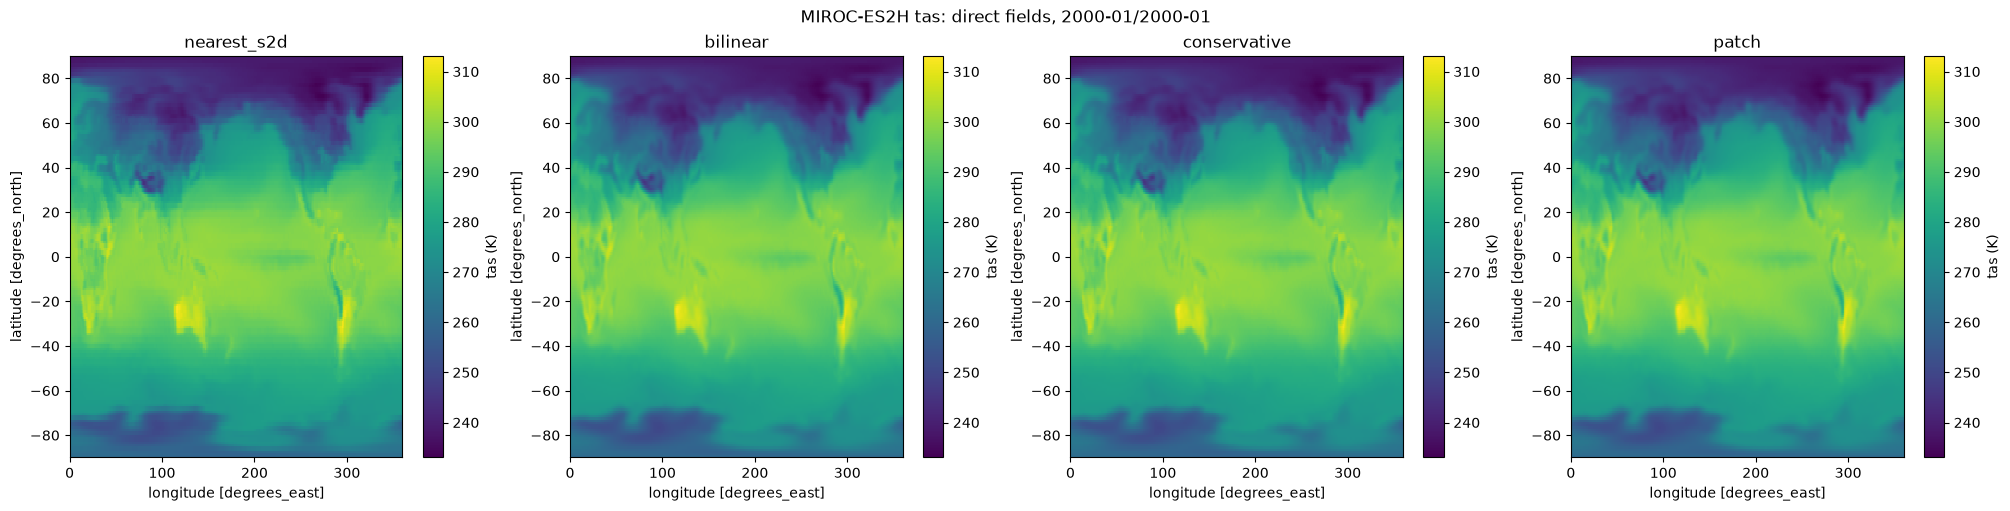

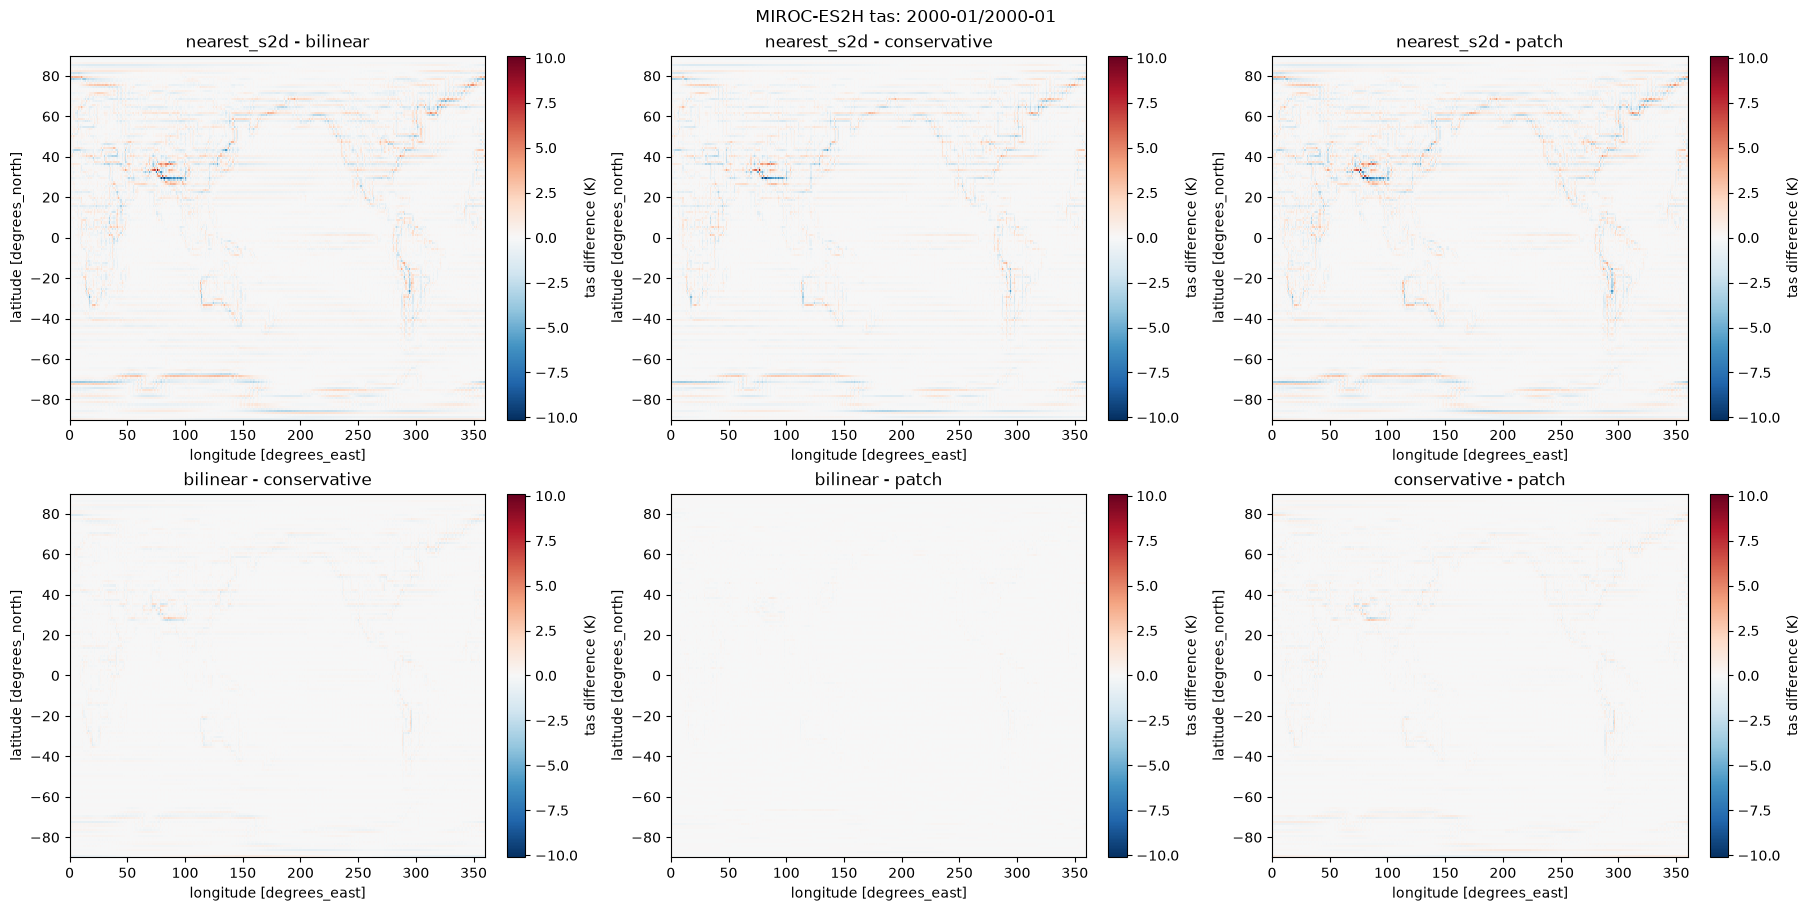

In [9]:
plot_case_differences("MIROC-ES2H tas")

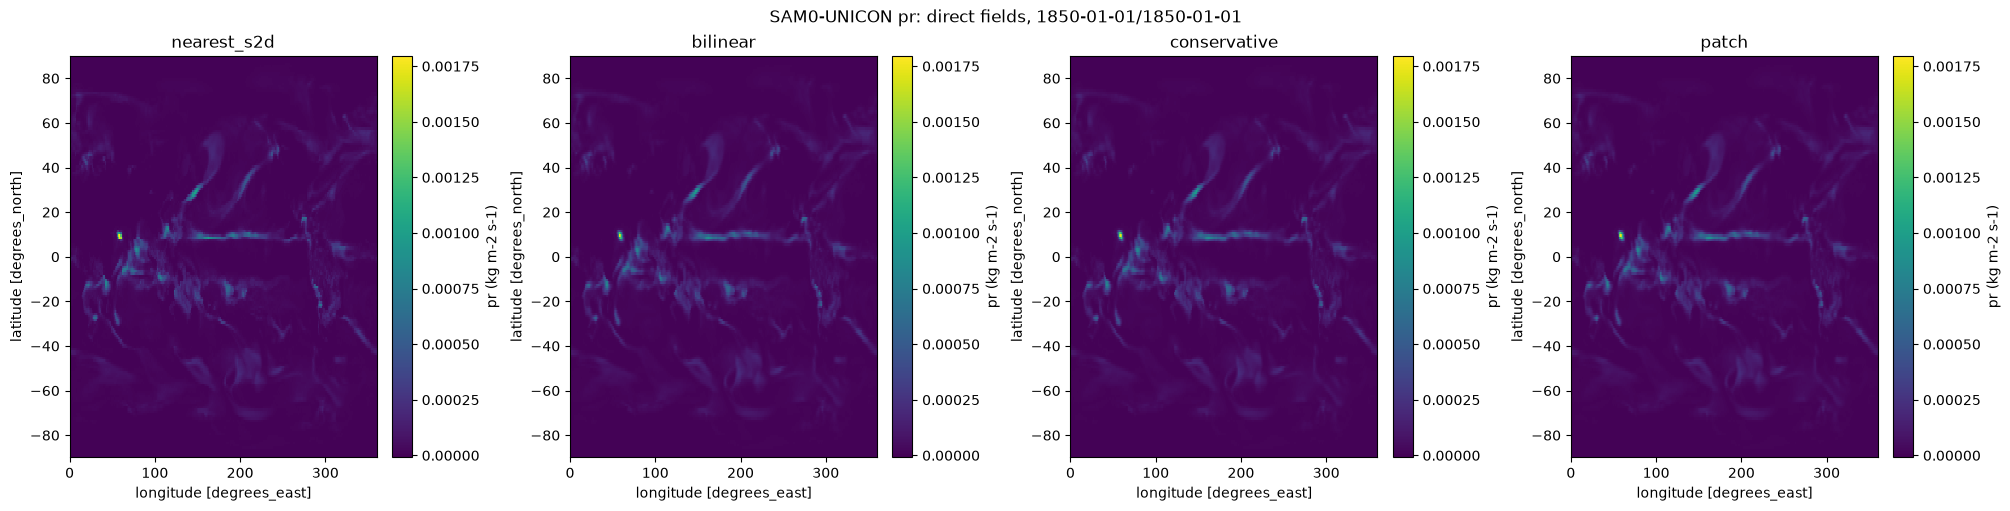

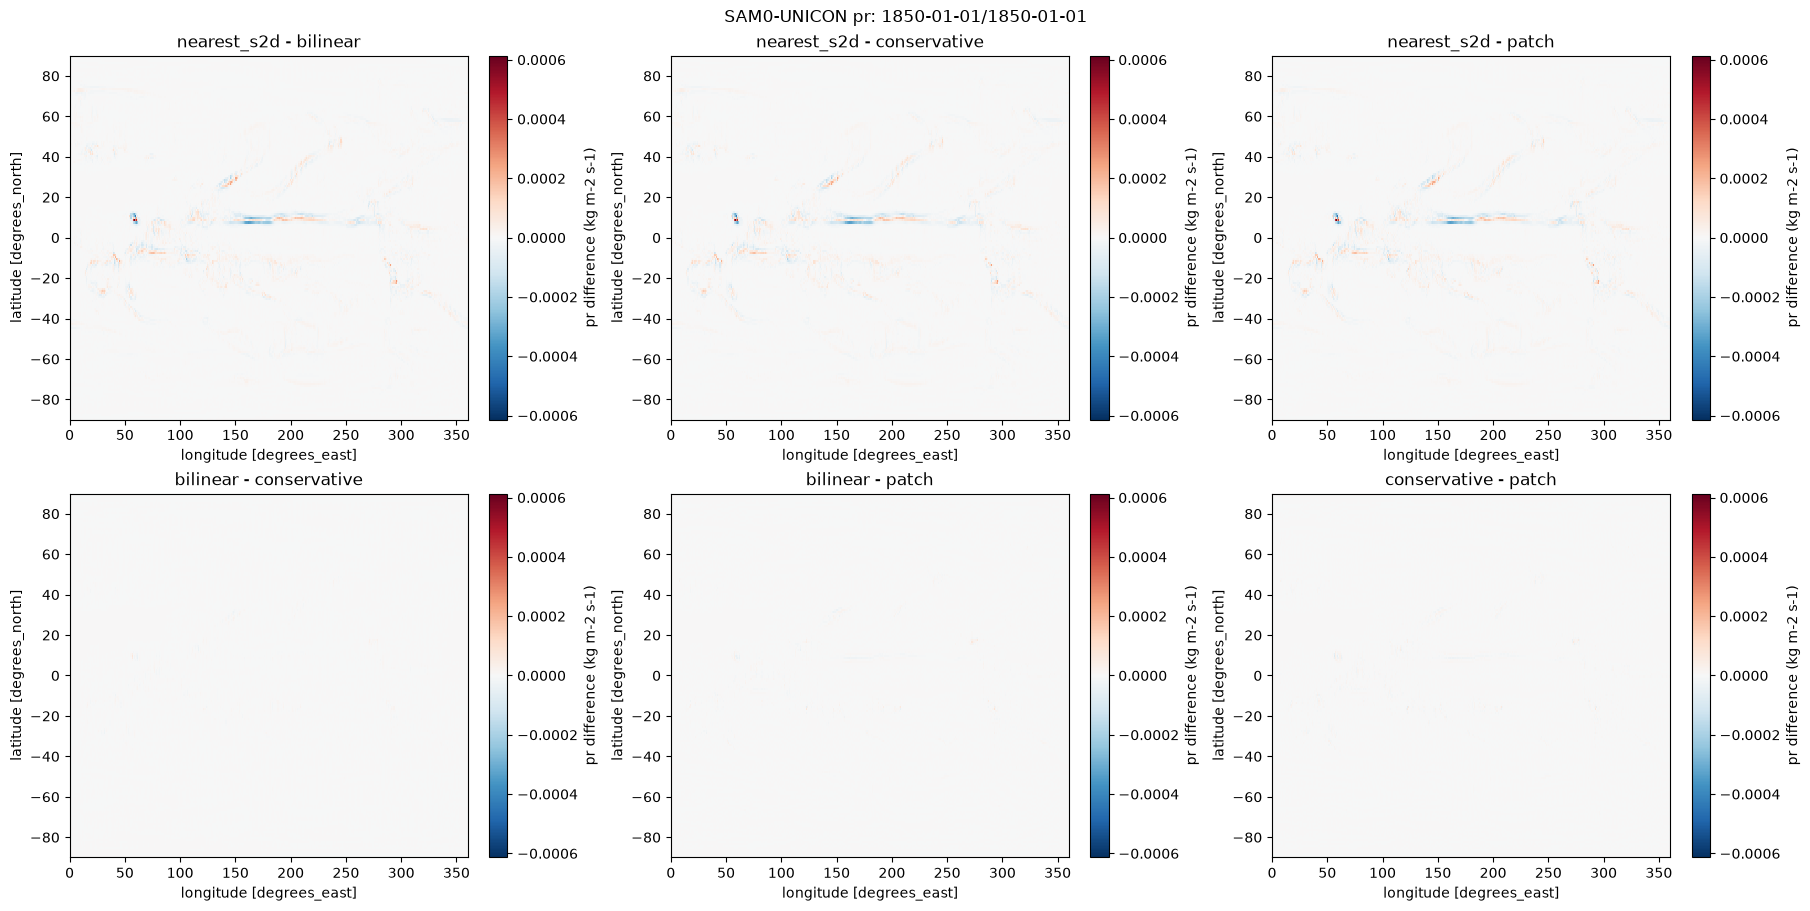

In [11]:
plot_case_differences("SAM0-UNICON pr")

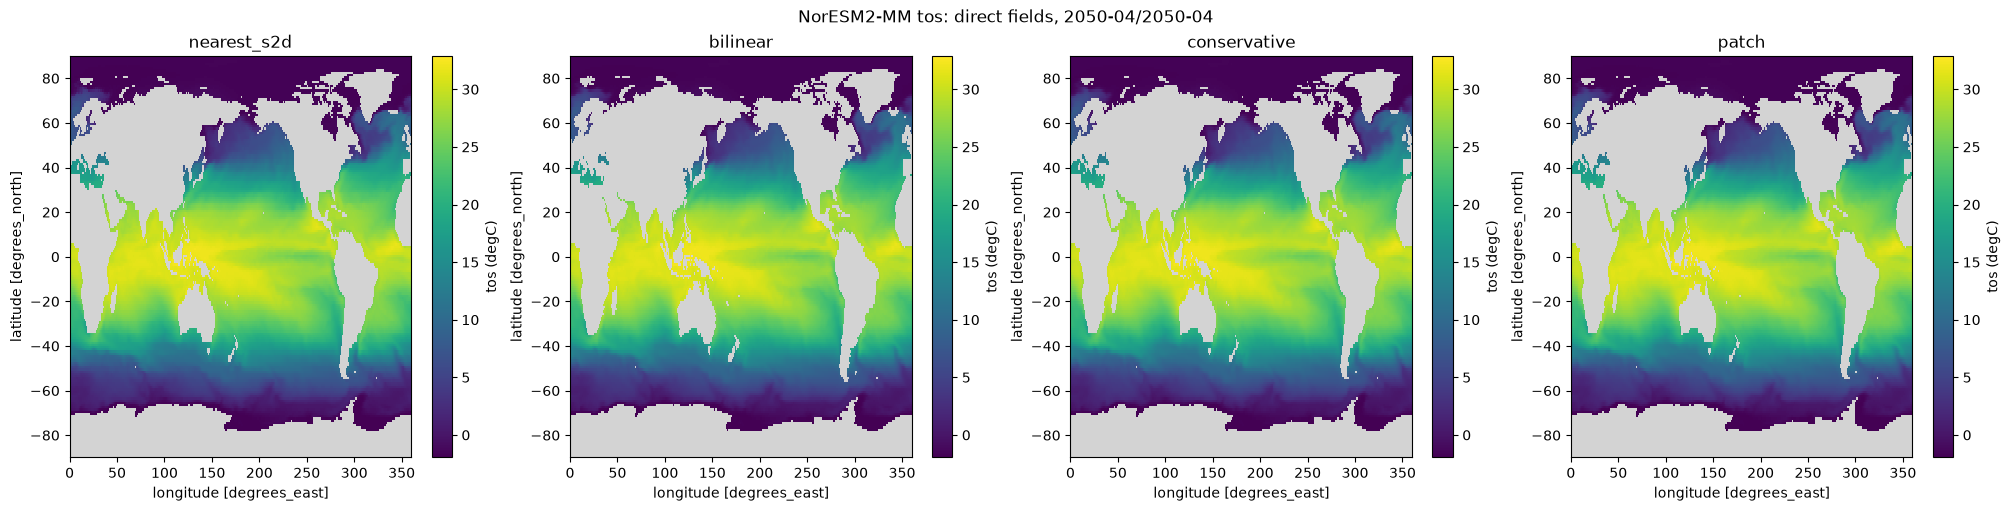

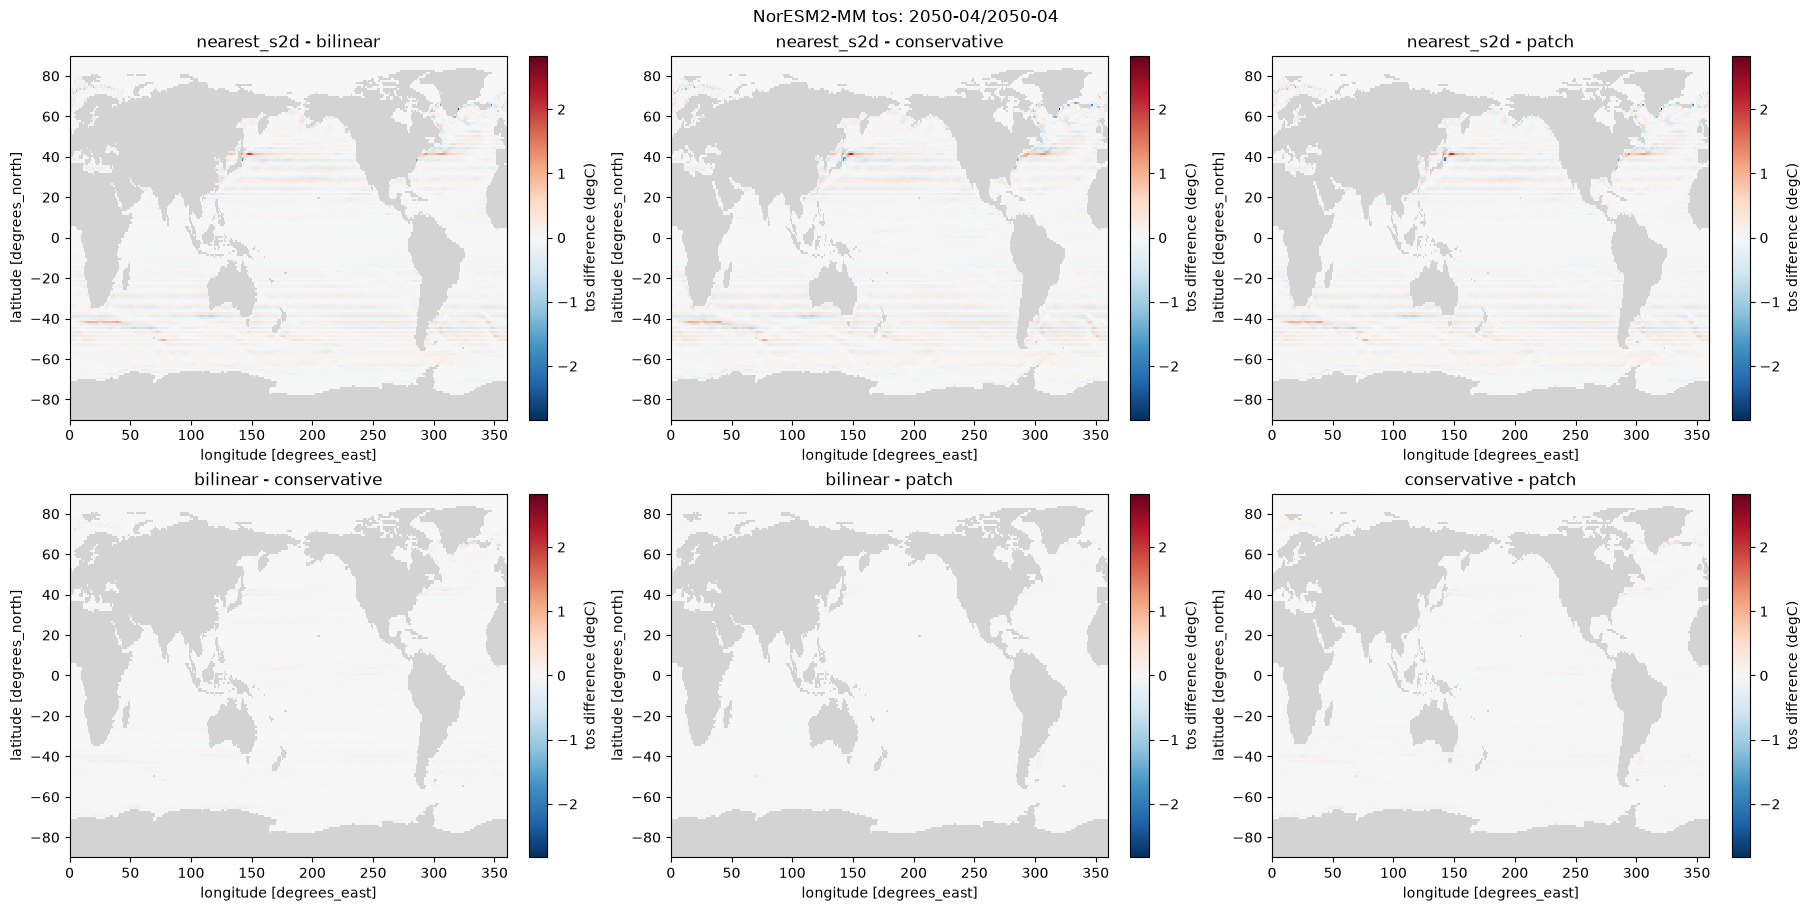

In [13]:
plot_case_differences("NorESM2-MM tos")

## Ocean-grid robustness and land-sea masks

The shared Word deliverables distinguish adaptive masking (renormalizing contributions from missing source cells) from a geographical target-grid mask. D.2.1.10 illustrates MPI-ESM1-2-LR ocean halos and IITM-ESM conservative-remapping artifacts. D.2.1.11 describes target-mask support for unstructured ocean grids, noting it was not yet formally released when the report was written.

**Live interface checked on 2026-11-13:** Rook exposes `collection`, `method`, `grid`, and `custom_grid`. `0pt5deg_lsm` is an allowed grid, but no mask selector or mask-file upload is exposed. Upstream clisops supports `mask='land'` (exclude land) and `mask='ocean'` (exclude ocean), using `sftlf`/`lsm` already in the target-grid dataset; the upstream Rook wrapper does not forward that selector. Selecting an `_lsm` grid alone does not demonstrate that a mask is applied.

Named grids and their bundled masks are resolved **on the server**: there is no need to download them on the Rooki client, nor an exposed way to pass a local mask to this service. A custom grid is numeric geometry, not an uploaded file. With clisops run locally instead, its grid/mask data must be available locally. The local mask below is downloaded only to assess coverage and demonstrate post-processing, not sent to Rook.

Two documented problematic ocean models are tested with all four methods on `1deg`. A controlled nearest-neighbour test compares `0pt5deg_lsm` against an equivalent custom 0.5-degree grid. Local post-masking cannot repair bad source-cell bounds, alter interpolation weights, or certify the unstructured-grid fixes. AWI-CM-1-1-MR `tos` was absent from the inspected C3S catalog, so that unstructured case is not tested.

Sources: [live WPS inputs](http://rook.dkrz.de/wps?service=WPS&version=1.0.0&request=DescribeProcess&identifier=regrid), [Rook wrapper](https://github.com/roocs/rook/blob/main/src/rook/operations/regrid.py), [clisops masking](https://github.com/roocs/clisops/blob/master/clisops/ops/regrid.py), [bundled grids](https://github.com/roocs/roocs-grids). Upstream source does not prove which backend version is deployed.

Run the earlier imports, `regrid_methods`, `additional_regrid_cases`, and `plot_case_differences` definitions first. Downloads are retained under `.cache/ocean-regrid` in the notebook's working directory. Land diagnostics use an explicit fractional-mask threshold of 0.5, not a model-specific coastline truth.

In [4]:
from pathlib import Path
from hashlib import sha256
from xml.etree import ElementTree as ET
import json
import requests
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ocean_cache = Path('.cache/ocean-regrid').resolve()
ocean_cache.mkdir(parents=True, exist_ok=True)
description = requests.get(os.environ['ROOK_URL'], params={
    'service': 'WPS', 'version': '1.0.0', 'request': 'DescribeProcess', 'identifier': 'regrid',
}, timeout=60)
description.raise_for_status()
root = ET.fromstring(description.content)
ns = {'ows': 'http://www.opengis.net/ows/1.1'}
ocean_inputs = {
    item.find('ows:Identifier', ns).text: [v.text for v in item.findall('.//ows:Value', ns)]
    for item in root.findall('.//DataInputs/Input')
}
print('Live regrid inputs:', ocean_inputs)
print('Local download cache:', ocean_cache)

ocean_cases = {
    'MPI-ESM1-2-LR tos': {
        'variable': 'tos', 'time_range': '2000-01/2000-01',
        'dataset_id': 'c3s-cmip6.CMIP.MPI-M.MPI-ESM1-2-LR.historical.r1i1p1f1.Omon.tos.gn.v20190710',
        'results': {},
    },
    'IITM-ESM tos': {
        'variable': 'tos', 'time_range': '2050-04/2050-04',
        'dataset_id': 'c3s-cmip6.ScenarioMIP.CCCR-IITM.IITM-ESM.ssp126.r1i1p1f1.Omon.tos.gn.v20201112',
        'results': {},
    },
}

def ocean_download(case_name, workflow, parameters):
    case = ocean_cases[case_name]
    request_key = json.dumps({
        'service': os.environ['ROOK_URL'], 'dataset': case['dataset_id'],
        'time': case['time_range'], **parameters,
    }, sort_keys=True)
    target = ocean_cache / (sha256(request_key.encode()).hexdigest()[:20] + '.nc')
    if not target.exists():
        print(f'Requesting {case_name}: {parameters}', flush=True)
        response = workflow.orchestrate()
        if not response.ok:
            raise RuntimeError(f'{case_name}, {parameters}: {response.status}')
        urls = response.download_urls()
        if len(urls) != 1:
            raise ValueError(f'Expected one ocean output, received {len(urls)}: {urls}')
        download = requests.get(urls[0], timeout=180)
        download.raise_for_status()
        pending = target.with_suffix('.download.nc')
        pending.write_bytes(download.content)
        with xr.open_dataset(pending) as downloaded:
            downloaded.load()
        pending.replace(target)
        target.with_suffix('.json').write_text(json.dumps({
            'request': json.loads(request_key), 'download_url': urls[0],
            'provenance_url': response.provenance(),
        }, indent=2))
    else:
        print('Using cached output:', target.name)
    with xr.open_dataset(target) as dataset:
        dataset = dataset.load()
    field = dataset[case['variable']]
    if ('time' in field.dims and field.sizes['time'] != 1) or int(np.isfinite(field).sum().item()) == 0:
        raise ValueError(f'{case_name}: expected a non-empty fixed field or single time slice')
    print('Output:', dict(field.sizes), 'units:', field.attrs.get('units'))
    print('Regrid metadata:', {k: v for k, v in dataset.attrs.items() if 'regrid' in k.lower()})
    return dataset

def ocean_source_workflow(case_name):
    case = ocean_cases[case_name]
    source = ops.Input(case['variable'], [case['dataset_id']])
    if case['time_range'] is not None:
        source = ops.Subset(source, time=case['time_range'])
    else:
        source = ops.Subset(source)
    return source

def ocean_regrid(case_name, method, grid, custom_grid=None):
    parameters = {'method': method, 'grid': grid}
    if custom_grid is not None:
        parameters['custom_grid'] = custom_grid
    workflow = ops.Regrid(ocean_source_workflow(case_name), **parameters)
    return ocean_download(case_name, workflow, parameters)

def ocean_native(case_name):
    return ocean_download(case_name, ocean_source_workflow(case_name), {'operation': 'native_subset'})

def test_ocean_case(case_name):
    case = ocean_cases[case_name]
    additional_regrid_cases[case_name] = case
    for method in regrid_methods:
        case['results'][method] = ocean_regrid(case_name, method, '1deg')
    display(pd.DataFrame([
        {'method': method, 'finite_cells': int(np.isfinite(ds.tos).sum().item()),
         'minimum': float(ds.tos.min().item()), 'maximum': float(ds.tos.max().item())}
        for method, ds in case['results'].items()
    ]))
    plot_case_differences(case_name)


Live regrid inputs: {'collection': [], 'method': ['nearest_s2d', 'bilinear', 'conservative', 'patch'], 'grid': ['auto', '0pt25deg', '0pt25deg_era5', '0pt5deg_lsm', '0pt625x0pt5deg', '0pt75deg', '1deg', '1pt25deg', '2pt5deg', 'custom'], 'custom_grid': []}
Local download cache: .cache/ocean-regrid


Requesting MPI-ESM1-2-LR tos: {'method': 'nearest_s2d', 'grid': '1deg'}


Output: {'time': 1, 'lat': 180, 'lon': 360} units: degC
Regrid metadata: {'regrid_operation': 'nearest_s2d_220x256_180x360_peri', 'regrid_tool': 'xESMF_v0.9.2', 'regrid_weights_uid': '626faa9a9db8d2c8f233f0bfad59ea5c_d24f4f689f12099406e6b95115553334_peri_skip-degen_nearest_s2d'}
Requesting MPI-ESM1-2-LR tos: {'method': 'bilinear', 'grid': '1deg'}


Output: {'time': 1, 'lat': 180, 'lon': 360} units: degC
Regrid metadata: {'regrid_operation': 'bilinear_220x256_180x360_peri', 'regrid_tool': 'xESMF_v0.9.2', 'regrid_weights_uid': '626faa9a9db8d2c8f233f0bfad59ea5c_d24f4f689f12099406e6b95115553334_peri_skip-degen_bilinear'}
Requesting MPI-ESM1-2-LR tos: {'method': 'conservative', 'grid': '1deg'}


Output: {'time': 1, 'lat': 180, 'lon': 360} units: degC
Regrid metadata: {'regrid_operation': 'conservative_220x256_180x360', 'regrid_tool': 'xESMF_v0.9.2', 'regrid_weights_uid': '626faa9a9db8d2c8f233f0bfad59ea5c_d24f4f689f12099406e6b95115553334_peri_skip-degen_conservative'}
Requesting MPI-ESM1-2-LR tos: {'method': 'patch', 'grid': '1deg'}


Output: {'time': 1, 'lat': 180, 'lon': 360} units: degC
Regrid metadata: {'regrid_operation': 'patch_220x256_180x360_peri', 'regrid_tool': 'xESMF_v0.9.2', 'regrid_weights_uid': '626faa9a9db8d2c8f233f0bfad59ea5c_d24f4f689f12099406e6b95115553334_peri_skip-degen_patch'}


,method,finite_cells,minimum,maximum
0,nearest_s2d,42679,-1.900000,31.807280
1,bilinear,40502,-1.900000,31.002617
2,conservative,42720,-1.900000,31.807280
3,patch,42716,-1.995098,31.645586


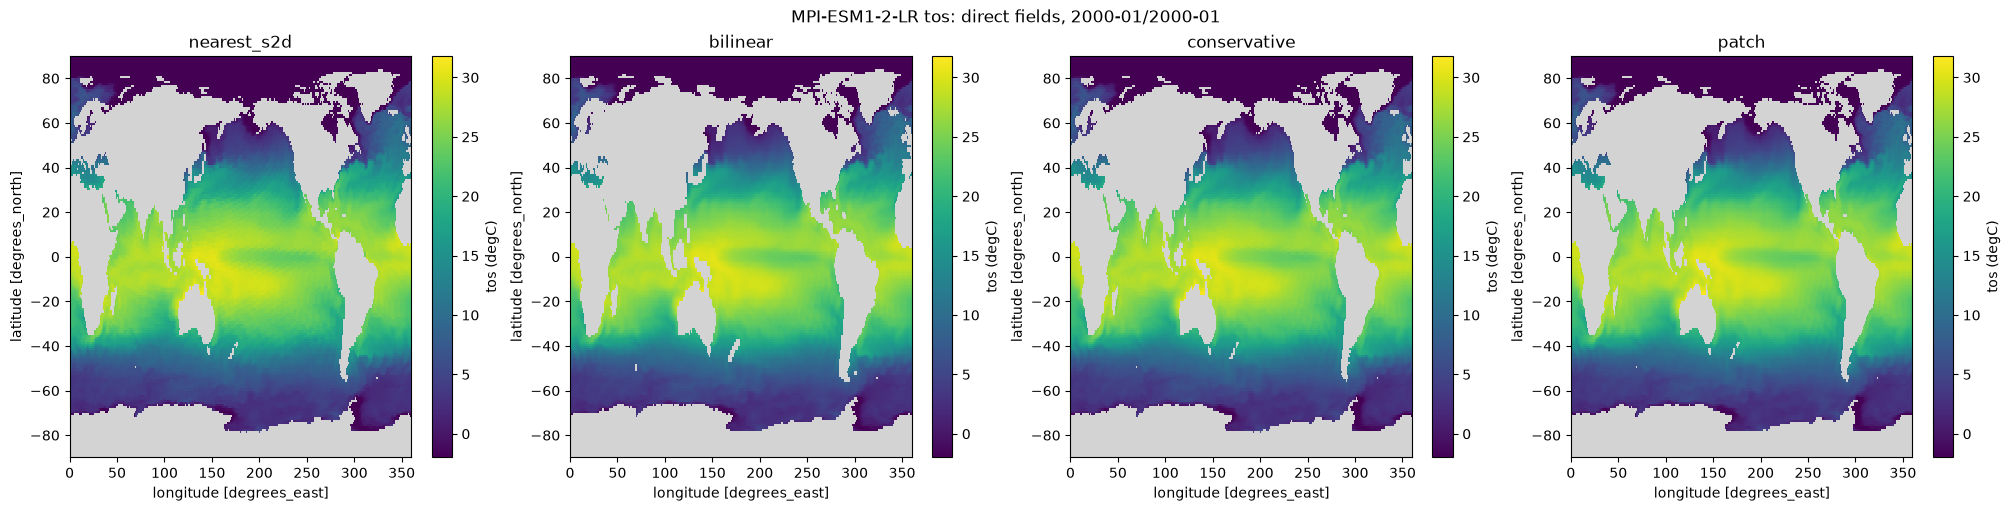

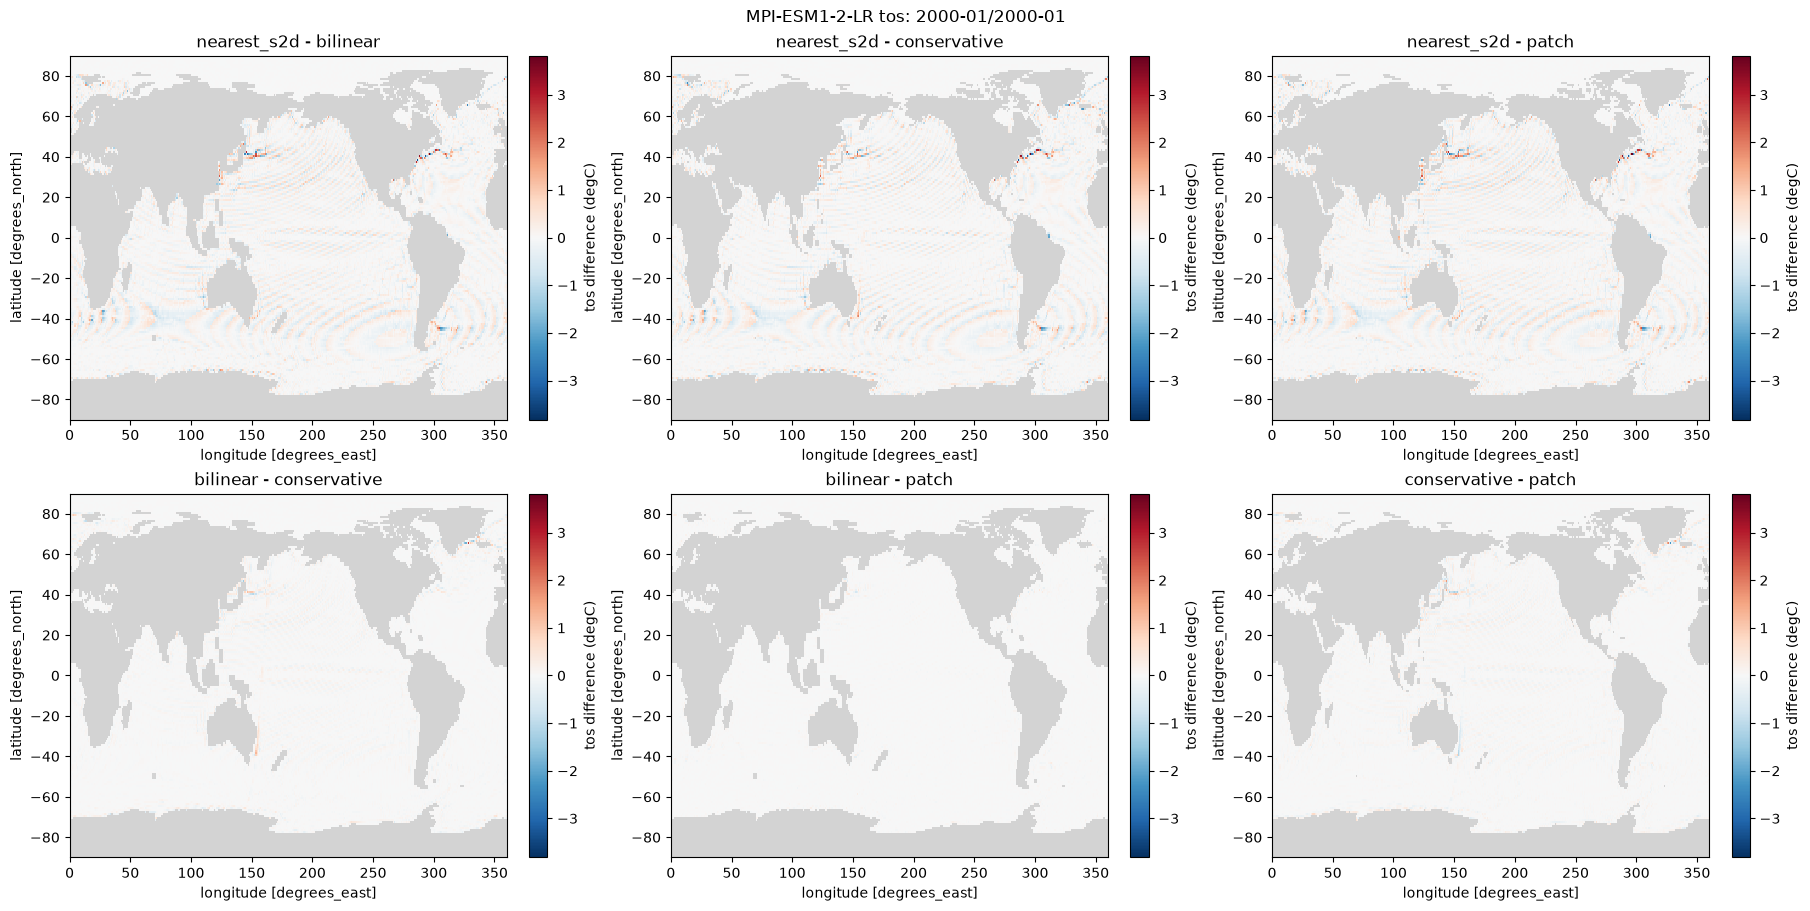

In [15]:
test_ocean_case('MPI-ESM1-2-LR tos')

Requesting IITM-ESM tos: {'method': 'nearest_s2d', 'grid': '1deg'}


Output: {'time': 1, 'lat': 180, 'lon': 360} units: degC
Regrid metadata: {'regrid_operation': 'nearest_s2d_200x360_180x360_peri', 'regrid_tool': 'xESMF_v0.9.2', 'regrid_weights_uid': '79b62aaa83a62338bbf5a1694b7a92ba_d24f4f689f12099406e6b95115553334_peri_skip-degen_nearest_s2d'}
Requesting IITM-ESM tos: {'method': 'bilinear', 'grid': '1deg'}


Output: {'time': 1, 'lat': 180, 'lon': 360} units: degC
Regrid metadata: {'regrid_operation': 'bilinear_200x360_180x360_peri', 'regrid_tool': 'xESMF_v0.9.2', 'regrid_weights_uid': '79b62aaa83a62338bbf5a1694b7a92ba_d24f4f689f12099406e6b95115553334_peri_skip-degen_bilinear'}
Requesting IITM-ESM tos: {'method': 'conservative', 'grid': '1deg'}


Output: {'time': 1, 'lat': 180, 'lon': 360} units: degC
Regrid metadata: {'regrid_operation': 'conservative_200x360_180x360', 'regrid_tool': 'xESMF_v0.9.2', 'regrid_weights_uid': 'd6d931466c8f04f508b87e8671c69533_d24f4f689f12099406e6b95115553334_peri_skip-degen_conservative'}
Requesting IITM-ESM tos: {'method': 'patch', 'grid': '1deg'}


Output: {'time': 1, 'lat': 180, 'lon': 360} units: degC
Regrid metadata: {'regrid_operation': 'patch_200x360_180x360_peri', 'regrid_tool': 'xESMF_v0.9.2', 'regrid_weights_uid': '79b62aaa83a62338bbf5a1694b7a92ba_d24f4f689f12099406e6b95115553334_peri_skip-degen_patch'}


,method,finite_cells,minimum,maximum
0,nearest_s2d,42320,-1.885377,31.697542
1,bilinear,40675,-1.881288,31.472113
2,conservative,41594,-1.885014,31.381258
3,patch,42300,-1.900879,31.422720


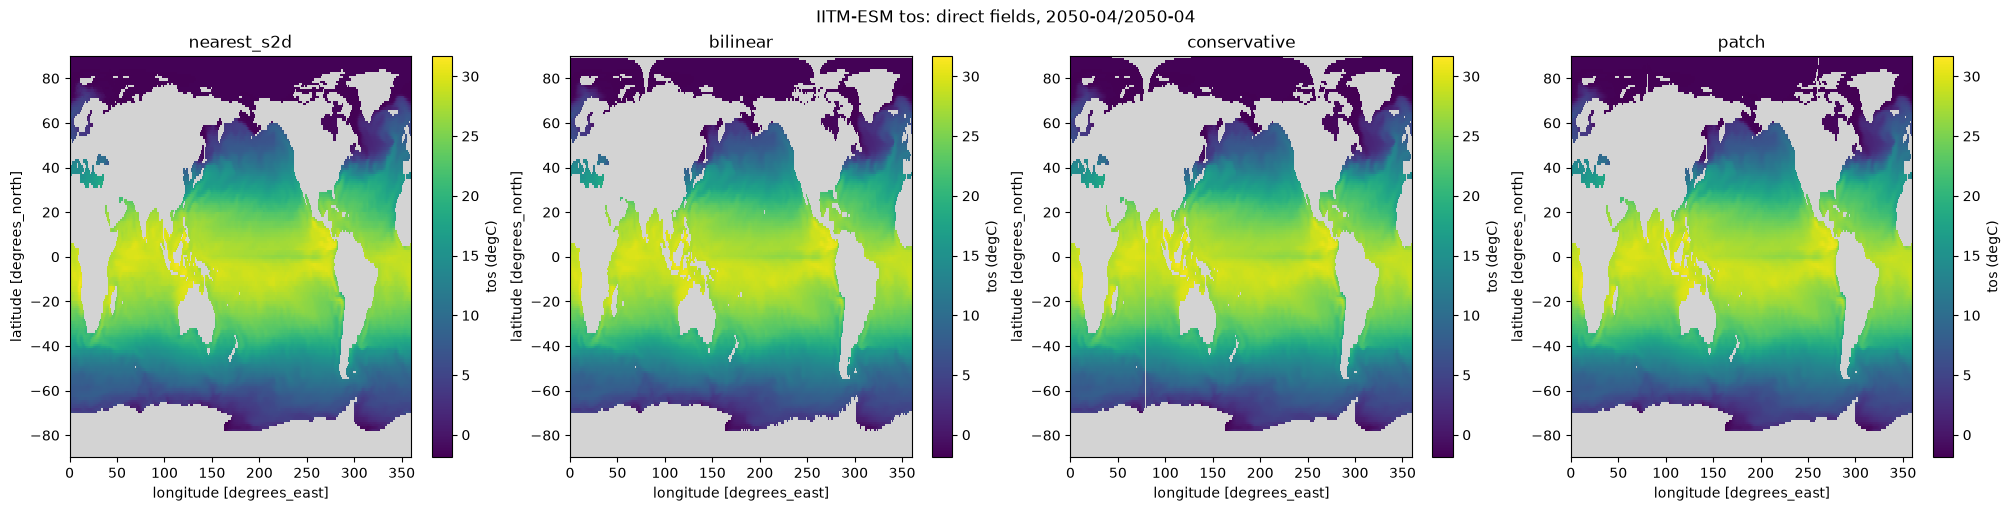

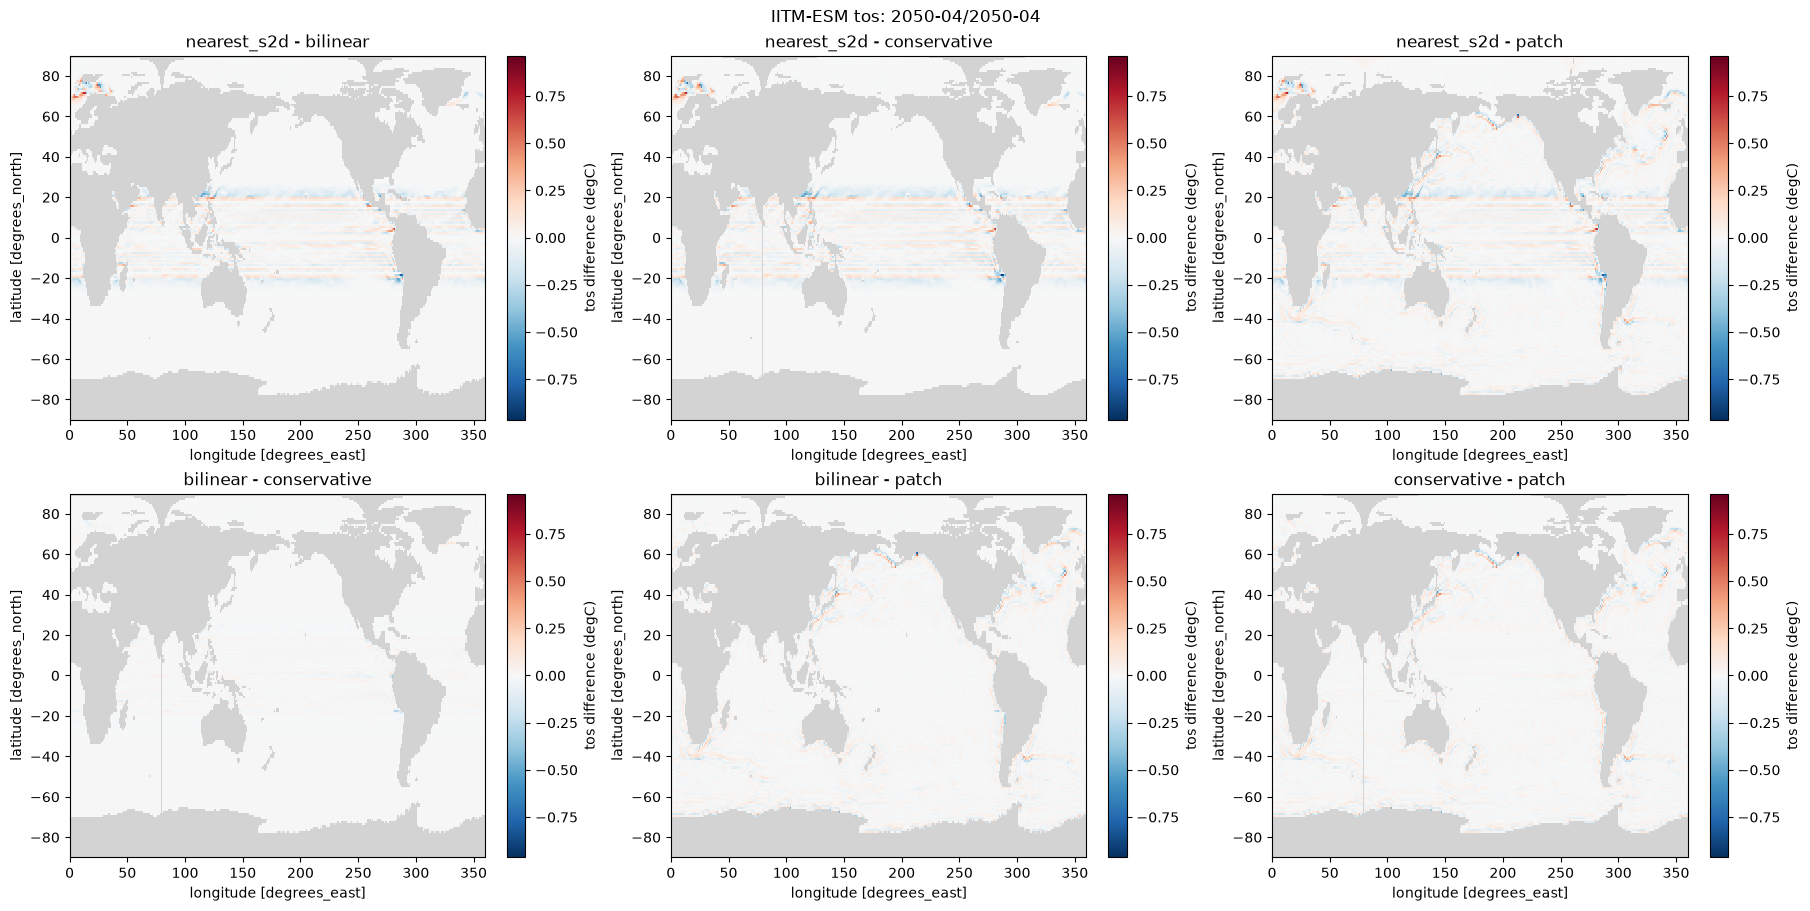

In [17]:
test_ocean_case('IITM-ESM tos')

### Does choosing the bundled mask grid actually mask land?

Compare nearest-neighbour MPI output on `custom_grid='0.5'` and `0pt5deg_lsm`. Normalize the longitude frame and require exact coordinates before comparing. Download the matching fractional land mask from roocs-grids for diagnostics only. A cell is counted as reference land when `sftlf >= 0.5`; coastlines can differ from the model's. No interpolation or nearest-coordinate matching of the mask is performed. Local post-masking is explicitly separate from the remote result.

Requesting MPI-ESM1-2-LR tos: {'method': 'nearest_s2d', 'grid': 'custom', 'custom_grid': '0.5'}


Output: {'time': 1, 'lat': 360, 'lon': 720} units: degC
Regrid metadata: {'regrid_operation': 'nearest_s2d_220x256_360x720_peri', 'regrid_tool': 'xESMF_v0.9.2', 'regrid_weights_uid': '626faa9a9db8d2c8f233f0bfad59ea5c_cd9e54c843c62f63ae02682bd6fd6189_peri_skip-degen_nearest_s2d'}
Requesting MPI-ESM1-2-LR tos: {'method': 'nearest_s2d', 'grid': '0pt5deg_lsm'}


Output: {'time': 1, 'lat': 360, 'lon': 720} units: degC
Regrid metadata: {'regrid_operation': 'nearest_s2d_220x256_360x720_peri', 'regrid_tool': 'xESMF_v0.9.2', 'regrid_weights_uid': '626faa9a9db8d2c8f233f0bfad59ea5c_8b4b7401e4af7f754440b68a8b9f7568_peri_skip-degen_nearest_s2d'}


Local reference mask: https://raw.githubusercontent.com/roocs/roocs-grids/main/roocs_grids/grids/land_sea_mask_05degree.nc4 sha256: d46ddada5931a5c7eb4e056c8af06edb66ddea70e09eca7bd0c56978fc3ca351


,result,finite_cells,finite_on_reference_land
0,custom 0.5 (remote),170694,7253
1,0pt5deg_lsm (remote),170694,7253
2,0pt5deg_lsm + LOCAL post-mask,163441,0


Finite/missing-mask disagreements: 0
Maximum absolute difference on common valid cells: 0.0
Reference-land cells: 94742 / 259200


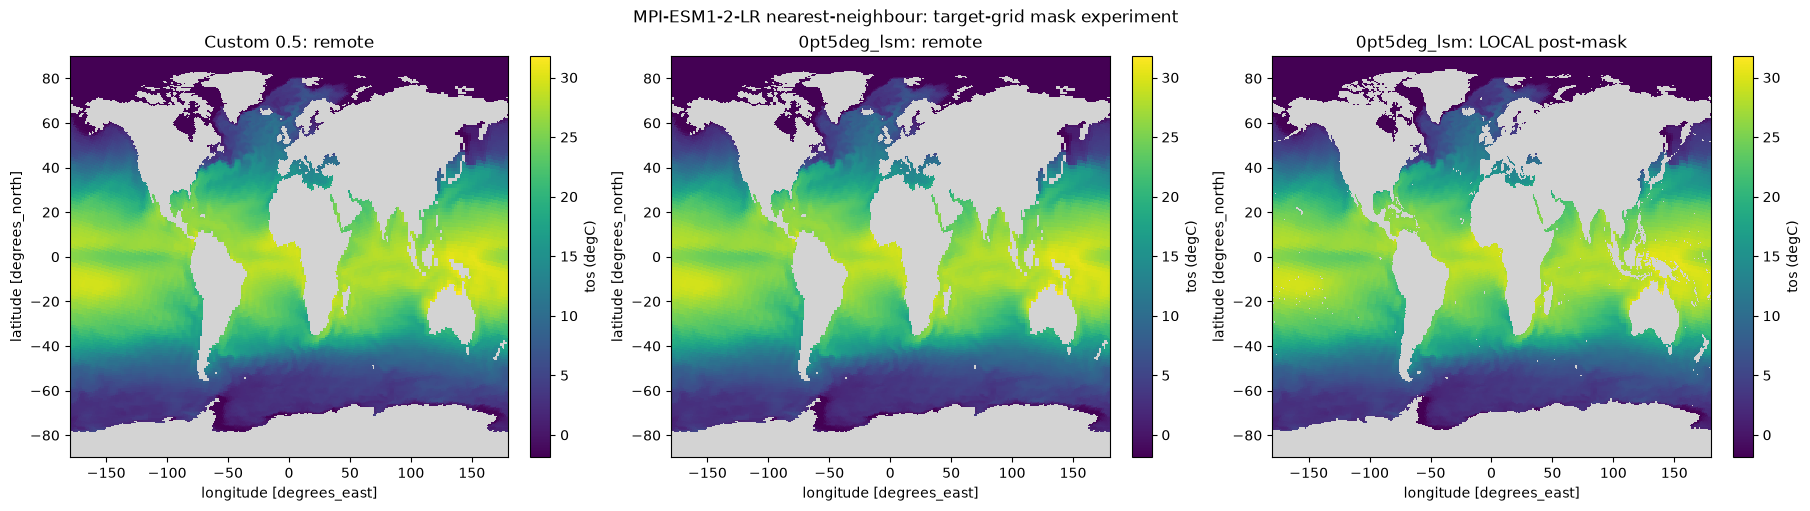

In [7]:
def canonical_ocean_grid(field):
    return field.assign_coords(lon=((field.lon + 180) % 360) - 180).sortby('lon').sortby('lat')

if '0pt5deg_lsm' not in ocean_inputs['grid'] or 'custom' not in ocean_inputs['grid']:
    raise ValueError('The live service no longer exposes both required target grids')
plain_half_degree = ocean_regrid('MPI-ESM1-2-LR tos', 'nearest_s2d', 'custom', '0.5')
bundled_mask_grid = ocean_regrid('MPI-ESM1-2-LR tos', 'nearest_s2d', '0pt5deg_lsm')
mask_url = 'https://raw.githubusercontent.com/roocs/roocs-grids/main/roocs_grids/grids/land_sea_mask_05degree.nc4'
mask_path = ocean_cache / 'land_sea_mask_05degree.nc4'
if not mask_path.exists():
    mask_download = requests.get(mask_url, timeout=60)
    mask_download.raise_for_status()
    mask_path.write_bytes(mask_download.content)
print('Local reference mask:', mask_url, 'sha256:', sha256(mask_path.read_bytes()).hexdigest())
with xr.open_dataset(mask_path) as mask_dataset:
    land_fraction = canonical_ocean_grid(mask_dataset.sftlf.load())
if not bool(np.isfinite(land_fraction).all()) or float(land_fraction.min()) < 0 or float(land_fraction.max()) > 1:
    raise ValueError('Expected a finite fractional reference mask in [0, 1]')
plain, bundled, land_fraction = xr.align(
    canonical_ocean_grid(plain_half_degree.tos.isel(time=0)),
    canonical_ocean_grid(bundled_mask_grid.tos.isel(time=0)),
    land_fraction, join='exact',
)
if plain.attrs.get('units') != bundled.attrs.get('units'):
    raise ValueError('Temperature units differ between target-grid experiments')
reference_land = land_fraction >= 0.5
locally_masked = bundled.where(~reference_land)
coverage = pd.DataFrame([
    {'result': name, 'finite_cells': int(np.isfinite(field).sum().item()),
     'finite_on_reference_land': int((np.isfinite(field) & reference_land).sum().item())}
    for name, field in [('custom 0.5 (remote)', plain), ('0pt5deg_lsm (remote)', bundled),
                        ('0pt5deg_lsm + LOCAL post-mask', locally_masked)]
])
display(coverage)
print('Finite/missing-mask disagreements:', int((np.isfinite(plain) != np.isfinite(bundled)).sum().item()))
target_difference = bundled - plain
print('Maximum absolute difference on common valid cells:', float(abs(target_difference).max(skipna=True).item()))
print('Reference-land cells:', int(reference_land.sum().item()), '/', reference_land.size)
assert int((np.isfinite(locally_masked) & reference_land).sum().item()) == 0

figure, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
vmin = min(float(plain.min().item()), float(bundled.min().item()))
vmax = max(float(plain.max().item()), float(bundled.max().item()))
for axis, (title, field) in zip(axes, [
    ('Custom 0.5: remote', plain), ('0pt5deg_lsm: remote', bundled),
    ('0pt5deg_lsm: LOCAL post-mask', locally_masked),
]):
    axis.set_facecolor('lightgrey')
    field.plot(ax=axis, vmin=vmin, vmax=vmax, cmap='viridis',
               cbar_kwargs={'label': f'tos ({bundled.attrs.get("units")})'})
    axis.set_title(title)
figure.suptitle('MPI-ESM1-2-LR nearest-neighbour: target-grid mask experiment')
plt.show()


### Observations from the 2026-11-13 ocean tests

- All four methods completed for MPI-ESM1-2-LR January 2000 and IITM-ESM April 2050 on `1deg`; their pairwise maps are saved above. Completion alone does not establish scientific correctness or conservation.
- The remote output metadata reports `regrid_tool = xESMF_v0.9.2`. This identifies the reported regridding tool, not the complete deployed clisops version or the status of all fixes in D.2.1.11.
- For MPI nearest-neighbour at 0.5 degrees, the custom grid and `0pt5deg_lsm` had exactly matching coordinates after longitude-frame normalization, identical finite/missing patterns, and maximum absolute difference **0.0 degC** on common valid cells. Both contained **7,253** finite values over reference-land cells (`sftlf >= 0.5`). Thus merely selecting `_lsm` did not produce the reference land exclusion in this experiment.
- Applying the downloaded reference mask **locally after regridding** reduced finite cells from **170,694 to 163,441**, with zero finite values remaining on reference land. The output was not sent back to Rook. This demonstrates post-masking only, not mask-aware interpolation or repaired ocean-grid geometry.
- The service has no exposed input for a chosen mask file or `mask='land'`. To control masking during weight generation, the server/wrapper would need to expose and forward that capability, or regridding would need to be run locally with clisops and a compatible target grid containing the intended mask. Local mask download is needed only for a local workflow or diagnostics, not to choose the server's bundled target grid.

These conclusions apply to the datasets, dates, grids, reference coastline and service tested here. In particular, the unstructured AWI ocean-grid masking described in D.2.1.11 remains unverified.

## Further ocean edge cases from the PDF deliverables

D.2.1.10 pp. 9-12 documents halos, collapsed/oversized cells and missing coordinates. We add its **exact** NorESM2-MM `simass` SSP126 dataset (p. 10, Figure 2) and EC-Earth3-Veg `deptho` SSP245 dataset (p. 11, Figure 3), rather than treating a `tos` field as a substitute. `simass` is sampled in April 2050; `deptho` is a fixed field and is requested without a time filter. The PDF figures do not specify a time slice, so identical maps to those figures are not expected.

Native-grid diagnostics cover the new cases and the earlier MPI/IITM examples: non-finite/out-of-range latitude coordinates, duplicate centres after rounding to six decimals, coordinate extents, bounds availability, cells with fewer than three unique finite vertices, and unusually wide cells. Longitude width is the shortest circular arc containing the vertices, independent of whether the centre exists. This handles the longitude seam but does not establish polygon connectivity or validity. The 50-degree span diagnostic is motivated by the >50-degree cell described on p. 10; it is a screening flag, not proof of invalid geometry. Duplicate centres are not automatically proven halos. These are diagnostics of the subset delivered by Rook, which may already have processed source metadata.

Output checks include exact `1deg` coordinates, expected dimensions, source/output units, infinities, finite coverage, negative values, and departures from the native data range (numerical tolerance: `1e-6 * max(1, abs(source minimum), abs(source maximum))`). Values outside the source range are reported, not automatically labelled erroneous. Ice-mass zero is physically meaningful and is **not** treated as missing. Pairwise plots use the common valid cells and do not show cells missing in just one method.

**Bounded method scope:** the new PDF cases compare `nearest_s2d`, `bilinear`, and `conservative`, as recommended by the report's geometry discussion. A NorESM2 `simass` `patch` request was submitted but had not returned after more than 13 minutes; local execution was stopped, with no remote cancellation API available. Its outcome is incomplete, not a confirmed algorithm failure. It is not automatically resubmitted below. `patch` is not requested for the new fixed-field case; the earlier `tos` patch tests remain available.

A final reference-land coverage table and map address D.2.1.10 section 3.10 and D.2.1.11 section 2.3. The generic land mask is a coastline diagnostic, not model-specific truth or a test of conservation. No area-integral conservation claim is made without native cell areas and matching integration domains.

**Explicit gaps:** the inspected C3S CMIP6 catalog (v20260203) has no AWI-CM-1-1-MR/AWI-ESM-1-1-LR `tos`, BCC-CSM2-MR `tos`, GFDL-OM4p5B `volcello`, GFDL-ESM4 `mlotst`, or IITM-ESM `thetao`. Thus the reports' unstructured-grid mask case, BCC CF-identification case, GFDL unmasked-coordinate case, and exact 1pctCO2 longitude examples remain untested. Staggered vector regridding and the CORDEX-specific fixes are outside these scalar-ocean tests. Native longitude diagnostics below can reveal related extent issues but are not substitutes for those exact unavailable experiments.

Run the earlier imports, `regrid_methods`, `additional_regrid_cases`, `plot_case_differences`, and ocean helper definitions first. All downloads remain in the existing persistent `.cache/ocean-regrid` cache.

In [5]:
import cf_xarray

ocean_cases.update({
    'NorESM2-MM simass edge case': {
        'variable': 'simass', 'time_range': '2050-04/2050-04',
        'methods': ['nearest_s2d', 'bilinear', 'conservative'],
        'dataset_id': 'c3s-cmip6.ScenarioMIP.NCC.NorESM2-MM.ssp126.r1i1p1f1.SImon.simass.gn.v20191108',
        'results': {},
    },
    'EC-Earth3-Veg deptho edge case': {
        'variable': 'deptho', 'time_range': None,
        'methods': ['nearest_s2d', 'bilinear', 'conservative'],
        'dataset_id': 'c3s-cmip6.ScenarioMIP.EC-Earth-Consortium.EC-Earth3-Veg.ssp245.r5i1p1f1.Ofx.deptho.gn.v20200312',
        'results': {},
    },
})
edge_native = {}
edge_grid_rows = []
edge_output_rows = []

def diagnose_ocean_grid(case_name, dataset):
    latitude = dataset.cf.coordinates.get('latitude', [])
    longitude = dataset.cf.coordinates.get('longitude', [])
    if len(latitude) != 1 or len(longitude) != 1:
        raise ValueError(f'{case_name}: ambiguous/missing CF coordinates: {latitude}, {longitude}')
    lat, lon = xr.broadcast(dataset[latitude[0]], dataset[longitude[0]])
    valid = np.isfinite(lat.values) & np.isfinite(lon.values)
    if not valid.any():
        raise ValueError(f'{case_name}: no finite native coordinate pairs')
    centres = np.round(np.column_stack([
        lat.values[valid], ((lon.values[valid] + 180) % 360) - 180,
    ]), 6)
    row = {
        'case': case_name, 'native_shape': str(lat.shape),
        'nonfinite_coordinate_pairs': int((~valid).sum()),
        'latitude_outside_90': int((np.isfinite(lat) & (abs(lat) > 90)).sum().item()),
        'duplicate_centres_6dp': len(centres) - len(np.unique(centres, axis=0)),
        'longitude_min': float(lon.min(skipna=True).item()),
        'longitude_max': float(lon.max(skipna=True).item()),
        'latitude_min': float(lat.min(skipna=True).item()),
        'latitude_max': float(lat.max(skipna=True).item()),
    }
    lat_bounds = dataset[latitude[0]].attrs.get('bounds')
    lon_bounds = dataset[longitude[0]].attrs.get('bounds')
    row['bounds_available'] = lat_bounds in dataset and lon_bounds in dataset
    if row['bounds_available']:
        lat_b, lon_b = xr.broadcast(dataset[lat_bounds], dataset[lon_bounds])
        vertex_dims = [dim for dim in lat_b.dims if dim not in lat.dims]
        if len(vertex_dims) != 1:
            raise ValueError(f'{case_name}: unexpected native bounds dimensions: {lat_b.dims}')
        vertex_dim = vertex_dims[0]
        lat_b = lat_b.transpose(*lat.dims, vertex_dim).values
        lon_b = lon_b.transpose(*lat.dims, vertex_dim).values
        finite_bounds = np.isfinite(lat_b).all(axis=-1) & np.isfinite(lon_b).all(axis=-1)
        corners = np.sort_complex(np.round(lat_b, 6) + 1j * np.round(((lon_b + 180) % 360) - 180, 6))
        unique_vertices = 1 + np.sum(corners[..., 1:] != corners[..., :-1], axis=-1)
        row['vertices_per_cell'] = lat_b.shape[-1]
        row['nonfinite_bound_cells'] = int((~finite_bounds).sum())
        row['fewer_than_3_unique_vertices'] = int(((unique_vertices < 3) & finite_bounds).sum())
        lat_span = np.ptp(lat_b, axis=-1)
        lon_angles = np.sort(lon_b % 360, axis=-1)
        lon_gaps = np.diff(np.concatenate([lon_angles, lon_angles[..., :1] + 360], axis=-1), axis=-1)
        lon_span = 360 - lon_gaps.max(axis=-1)
        row['latitude_span_over_50deg'] = int(((lat_span > 50) & finite_bounds).sum())
        row['longitude_span_over_50deg'] = int(((lon_span > 50) & finite_bounds).sum())
        row['max_latitude_span'] = float(lat_span[finite_bounds].max()) if finite_bounds.any() else np.nan
        row['max_longitude_span'] = float(lon_span[finite_bounds].max()) if finite_bounds.any() else np.nan
    return row

def run_documented_ocean_case(case_name):
    case = ocean_cases[case_name]
    native = ocean_native(case_name)
    edge_native[case_name] = native
    grid_row = diagnose_ocean_grid(case_name, native)
    edge_grid_rows.append(grid_row)
    display(pd.DataFrame([grid_row]).T)
    additional_regrid_cases[case_name] = case
    source_field = native[case['variable']]
    source_min = float(source_field.min(skipna=True).item())
    source_max = float(source_field.max(skipna=True).item())
    tolerance = 1e-6 * max(1, abs(source_min), abs(source_max))
    for method in case['methods']:
        result = ocean_regrid(case_name, method, '1deg')
        case['results'][method] = result
        field = result[case['variable']]
        expected_dims = ('time', 'lat', 'lon') if case['time_range'] is not None else ('lat', 'lon')
        if field.dims != expected_dims or field.sizes['lat'] != 180 or field.sizes['lon'] != 360:
            raise ValueError(f'{case_name}/{method}: unexpected output dimensions {field.sizes}')
        np.testing.assert_allclose(field.lat, np.arange(-89.5, 90, 1), rtol=0, atol=1e-8)
        np.testing.assert_allclose(field.lon, np.arange(0.5, 360, 1), rtol=0, atol=1e-8)
        if field.attrs.get('units') != source_field.attrs.get('units'):
            raise ValueError(f'{case_name}/{method}: native/output units differ')
        if bool(np.isinf(field).any()):
            raise ValueError(f'{case_name}/{method}: infinite output values')
        edge_output_rows.append({
            'case': case_name, 'method': method, 'units': field.attrs.get('units'),
            'finite_cells': int(np.isfinite(field).sum().item()),
            'source_min': source_min, 'source_max': source_max,
            'output_min': float(field.min(skipna=True).item()),
            'output_max': float(field.max(skipna=True).item()),
            'negative_cells': int((field < 0).sum().item()),
            'below_source_range': int((field < source_min - tolerance).sum().item()),
            'above_source_range': int((field > source_max + tolerance).sum().item()),
        })
    display(pd.DataFrame([row for row in edge_output_rows if row['case'] == case_name]))
    plot_case_differences(case_name)


Using cached output: 8607ebca5ebbd03ee390.nc


Output: {'time': 1, 'j': 384, 'i': 360} units: kg m-2
Regrid metadata: {}


,0
case,NorESM2-MM simass edge case
native_shape,"(384, 360)"
nonfinite_coordinate_pairs,39852
latitude_outside_90,0
duplicate_centres_6dp,0
longitude_min,0.003662
longitude_max,359.989471
latitude_min,-79.02993
latitude_max,89.757492
bounds_available,True


Using cached output: 6dd26fa223fce2bb3486.nc


Output: {'time': 1, 'lat': 180, 'lon': 360} units: kg m-2
Regrid metadata: {'regrid_operation': 'nearest_s2d_384x360_180x360_peri', 'regrid_tool': 'xESMF_v0.9.2', 'regrid_weights_uid': '24c3f505b565bef77b37716b1041bb04_d24f4f689f12099406e6b95115553334_peri_skip-degen_nearest_s2d'}
Using cached output: 08e855587f222c13b806.nc
Output: {'time': 1, 'lat': 180, 'lon': 360} units: kg m-2
Regrid metadata: {'regrid_operation': 'bilinear_384x360_180x360_peri', 'regrid_tool': 'xESMF_v0.9.2', 'regrid_weights_uid': '24c3f505b565bef77b37716b1041bb04_d24f4f689f12099406e6b95115553334_peri_skip-degen_bilinear'}
Using cached output: 2956a9eaa30579483a1c.nc
Output: {'time': 1, 'lat': 180, 'lon': 360} units: kg m-2
Regrid metadata: {'regrid_operation': 'conservative_384x360_180x360', 'regrid_tool': 'xESMF_v0.9.2', 'regrid_weights_uid': '24c3f505b565bef77b37716b1041bb04_d24f4f689f12099406e6b95115553334_peri_skip-degen_conservative'}


,case,method,units,finite_cells,source_min,source_max,output_min,output_max,negative_cells,below_source_range,above_source_range
0,NorESM2-MM simass edge case,nearest_s2d,kg m-2,42773,0.0,31949.681641,0.0,31949.681641,0,0,0
1,NorESM2-MM simass edge case,bilinear,kg m-2,41200,0.0,31949.681641,0.0,28994.107422,0,0,0
2,NorESM2-MM simass edge case,conservative,kg m-2,44879,0.0,31949.681641,0.0,21515.367188,0,0,0


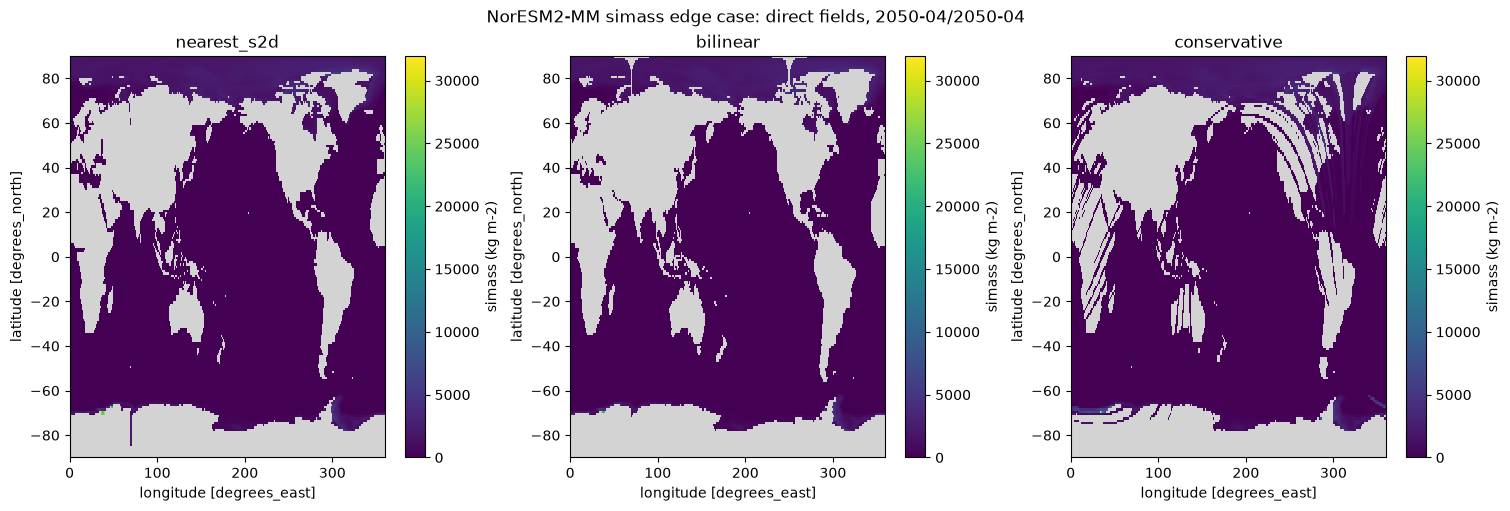

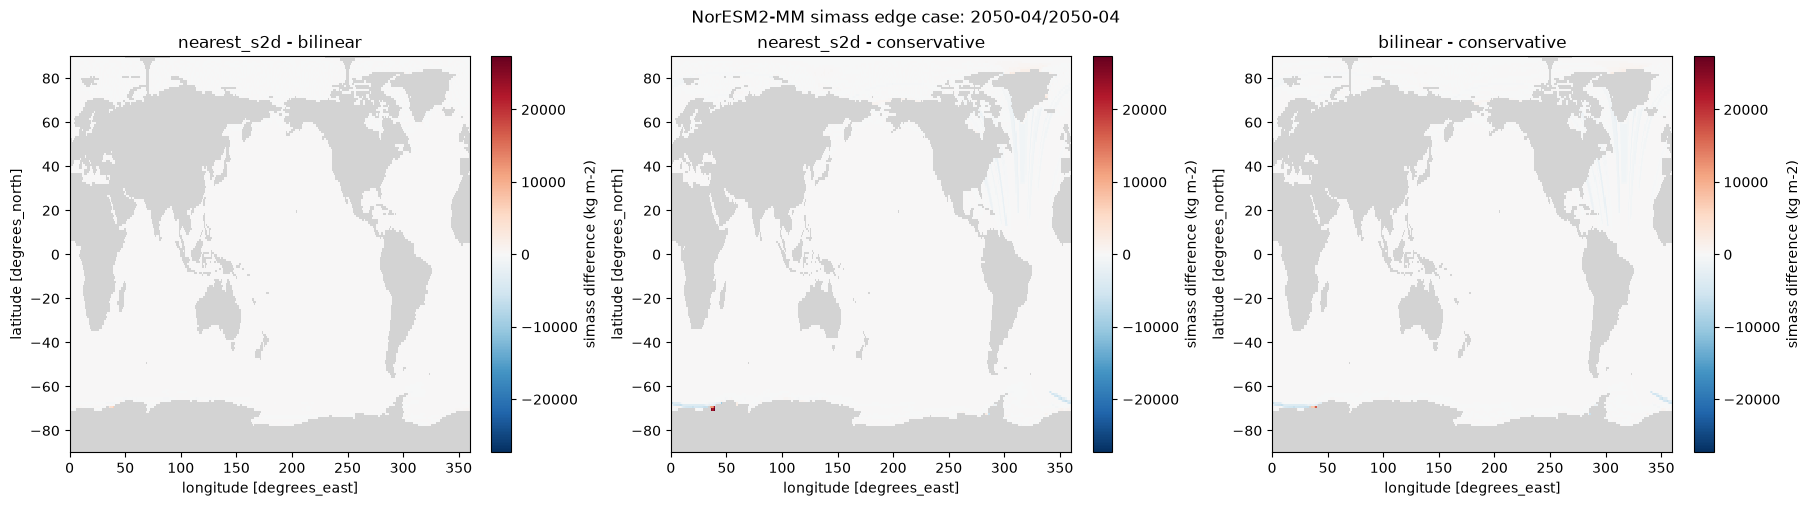

In [19]:
run_documented_ocean_case('NorESM2-MM simass edge case')

Using cached output: d2f1bffe0b28675ecab8.nc
Output: {'j': 292, 'i': 362} units: m
Regrid metadata: {}


,0
case,EC-Earth3-Veg deptho edge case
native_shape,"(292, 362)"
nonfinite_coordinate_pairs,0
latitude_outside_90,0
duplicate_centres_6dp,1408
longitude_min,0.0
longitude_max,359.994925
latitude_min,-78.57995
latitude_max,89.74177
bounds_available,True


Using cached output: 2eec1a99b2ca28e06bc3.nc
Output: {'lat': 180, 'lon': 360} units: m
Regrid metadata: {'regrid_operation': 'nearest_s2d_292x362_180x360_peri', 'regrid_tool': 'xESMF_v0.9.2', 'regrid_weights_uid': '7ea27f9d3a80899ca561612bf39c5ece_d24f4f689f12099406e6b95115553334_peri_skip-degen_nearest_s2d'}
Using cached output: 3d38128fd117e6e6c706.nc
Output: {'lat': 180, 'lon': 360} units: m
Regrid metadata: {'regrid_operation': 'bilinear_292x362_180x360_peri', 'regrid_tool': 'xESMF_v0.9.2', 'regrid_weights_uid': '7ea27f9d3a80899ca561612bf39c5ece_d24f4f689f12099406e6b95115553334_peri_skip-degen_bilinear'}
Using cached output: f128a1a827e3c49244e8.nc
Output: {'lat': 180, 'lon': 360} units: m
Regrid metadata: {'regrid_operation': 'conservative_292x362_180x360', 'regrid_tool': 'xESMF_v0.9.2', 'regrid_weights_uid': '7ea27f9d3a80899ca561612bf39c5ece_d24f4f689f12099406e6b95115553334_peri_skip-degen_conservative'}


,case,method,units,finite_cells,source_min,source_max,output_min,output_max,negative_cells,below_source_range,above_source_range
0,EC-Earth3-Veg deptho edge case,nearest_s2d,m,64800,0.0,7660.0,0.0,7660.000000,0,0,0
1,EC-Earth3-Veg deptho edge case,bilinear,m,64077,0.0,7660.0,0.0,7301.812012,0,0,0
2,EC-Earth3-Veg deptho edge case,conservative,m,60417,0.0,7660.0,0.0,7295.059082,0,0,0


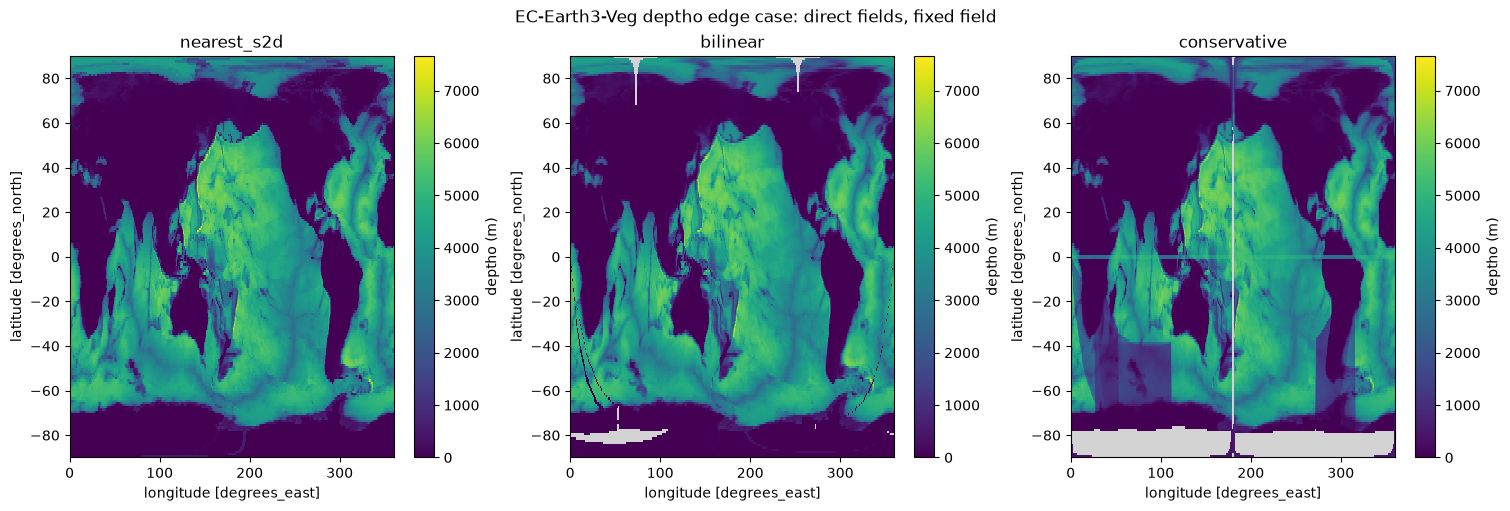

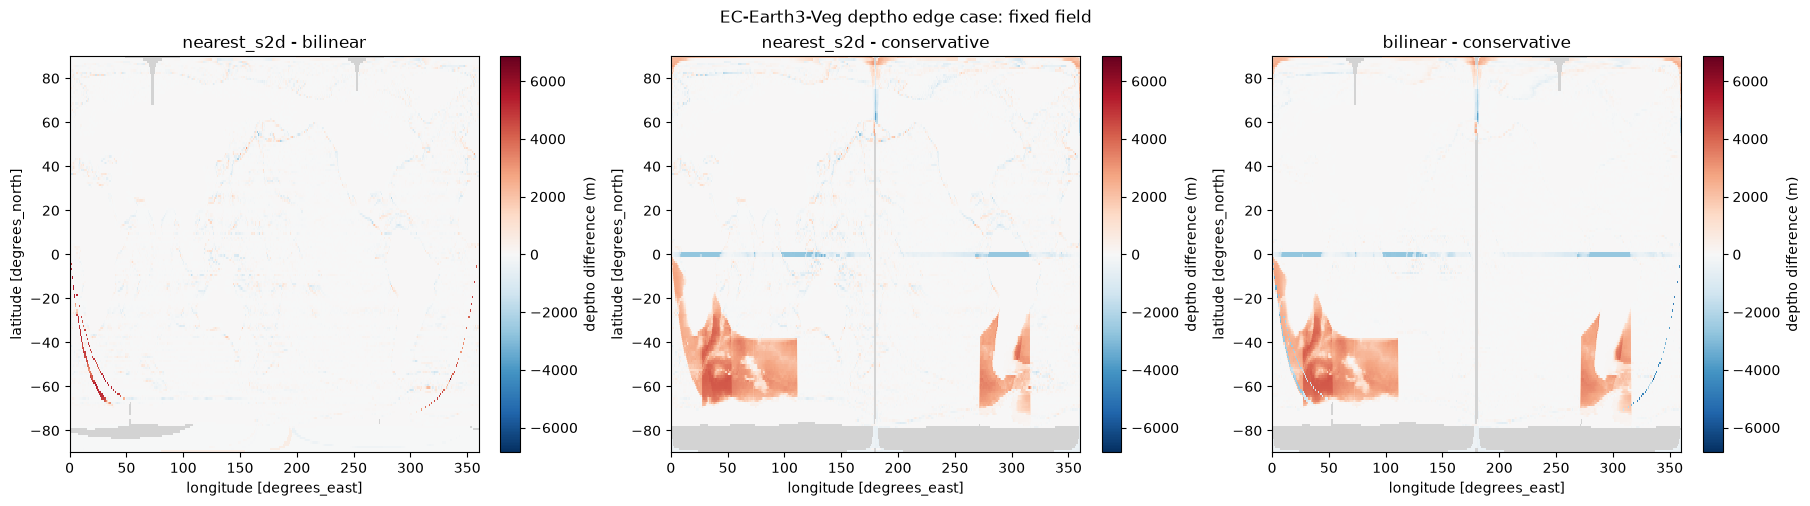

In [21]:
run_documented_ocean_case('EC-Earth3-Veg deptho edge case')

In [8]:
for case_name in ['MPI-ESM1-2-LR tos', 'IITM-ESM tos']:
    native = ocean_native(case_name)
    edge_native[case_name] = native
    edge_grid_rows.append(diagnose_ocean_grid(case_name, native))
    for method in regrid_methods:
        ocean_cases[case_name]['results'][method] = ocean_regrid(case_name, method, '1deg')
display(pd.DataFrame(edge_grid_rows).set_index('case').T)
display(pd.DataFrame(edge_output_rows))


Using cached output: 0604a9d831656aea036a.nc
Output: {'time': 1, 'j': 220, 'i': 256} units: degC
Regrid metadata: {}
Using cached output: c42493466aa4d157e2f9.nc
Output: {'time': 1, 'lat': 180, 'lon': 360} units: degC
Regrid metadata: {'regrid_operation': 'nearest_s2d_220x256_180x360_peri', 'regrid_tool': 'xESMF_v0.9.2', 'regrid_weights_uid': '626faa9a9db8d2c8f233f0bfad59ea5c_d24f4f689f12099406e6b95115553334_peri_skip-degen_nearest_s2d'}
Using cached output: fbf9b3171784986582f9.nc
Output: {'time': 1, 'lat': 180, 'lon': 360} units: degC
Regrid metadata: {'regrid_operation': 'bilinear_220x256_180x360_peri', 'regrid_tool': 'xESMF_v0.9.2', 'regrid_weights_uid': '626faa9a9db8d2c8f233f0bfad59ea5c_d24f4f689f12099406e6b95115553334_peri_skip-degen_bilinear'}
Using cached output: 50665518477462afc321.nc
Output: {'time': 1, 'lat': 180, 'lon': 360} units: degC
Regrid metadata: {'regrid_operation': 'conservative_220x256_180x360', 'regrid_tool': 'xESMF_v0.9.2', 'regrid_weights_uid': '626faa9a9db8d2

Output: {'time': 1, 'y': 200, 'x': 360} units: degC
Regrid metadata: {}
Using cached output: fc3d0e3232b8b2f233c6.nc
Output: {'time': 1, 'lat': 180, 'lon': 360} units: degC
Regrid metadata: {'regrid_operation': 'nearest_s2d_200x360_180x360_peri', 'regrid_tool': 'xESMF_v0.9.2', 'regrid_weights_uid': '79b62aaa83a62338bbf5a1694b7a92ba_d24f4f689f12099406e6b95115553334_peri_skip-degen_nearest_s2d'}
Using cached output: 9ba72b58835cccf39e1c.nc
Output: {'time': 1, 'lat': 180, 'lon': 360} units: degC
Regrid metadata: {'regrid_operation': 'bilinear_200x360_180x360_peri', 'regrid_tool': 'xESMF_v0.9.2', 'regrid_weights_uid': '79b62aaa83a62338bbf5a1694b7a92ba_d24f4f689f12099406e6b95115553334_peri_skip-degen_bilinear'}
Using cached output: cf5261d07ff81fb124b6.nc
Output: {'time': 1, 'lat': 180, 'lon': 360} units: degC
Regrid metadata: {'regrid_operation': 'conservative_200x360_180x360', 'regrid_tool': 'xESMF_v0.9.2', 'regrid_weights_uid': 'd6d931466c8f04f508b87e8671c69533_d24f4f689f12099406e6b95115

case,NorESM2-MM simass edge case,EC-Earth3-Veg deptho edge case,MPI-ESM1-2-LR tos,IITM-ESM tos
native_shape,"(384, 360)","(292, 362)","(220, 256)","(200, 360)"
nonfinite_coordinate_pairs,39852,0,0,0
latitude_outside_90,0,0,0,0
duplicate_centres_6dp,0,1408,440,0
longitude_min,0.003662,0.0,0.007175,-279.980316
longitude_max,359.989471,359.994925,359.996041,79.980324
latitude_min,-79.02993,-78.57995,-83.96551,-81.5
latitude_max,89.757492,89.74177,89.726604,89.487862
bounds_available,True,True,True,False
vertices_per_cell,4.0,4.0,4.0,NaN


,case,method,units,finite_cells,source_min,source_max,output_min,output_max,negative_cells,below_source_range,above_source_range
0,NorESM2-MM simass edge case,nearest_s2d,kg m-2,42773,0.0,31949.681641,0.0,31949.681641,0,0,0
1,NorESM2-MM simass edge case,bilinear,kg m-2,41200,0.0,31949.681641,0.0,28994.107422,0,0,0
2,NorESM2-MM simass edge case,conservative,kg m-2,44879,0.0,31949.681641,0.0,21515.367188,0,0,0
3,EC-Earth3-Veg deptho edge case,nearest_s2d,m,64800,0.0,7660.000000,0.0,7660.000000,0,0,0
4,EC-Earth3-Veg deptho edge case,bilinear,m,64077,0.0,7660.000000,0.0,7301.812012,0,0,0
5,EC-Earth3-Veg deptho edge case,conservative,m,60417,0.0,7660.000000,0.0,7295.059082,0,0,0


Reference coastline: https://raw.githubusercontent.com/roocs/roocs-grids/main/roocs_grids/grids/land_sea_mask_1degree.nc4 sha256: f3ab2aaf07dbcdd8be56329f434b14c563521c58071ecdbb23b19f8914ed4223


,case,method,finite_reference_land,nonzero_reference_land,missing_reference_ocean
0,MPI-ESM1-2-LR tos,nearest_s2d,2277,2277,141
1,MPI-ESM1-2-LR tos,bilinear,927,927,968
2,MPI-ESM1-2-LR tos,conservative,2297,2297,120
3,MPI-ESM1-2-LR tos,patch,2283,2283,110
4,IITM-ESM tos,nearest_s2d,1902,1902,125
5,IITM-ESM tos,bilinear,1261,1261,1129
6,IITM-ESM tos,conservative,1883,1883,832
7,IITM-ESM tos,patch,1896,1896,139
8,NorESM2-MM simass edge case,nearest_s2d,2288,1098,58
9,NorESM2-MM simass edge case,bilinear,1167,573,510


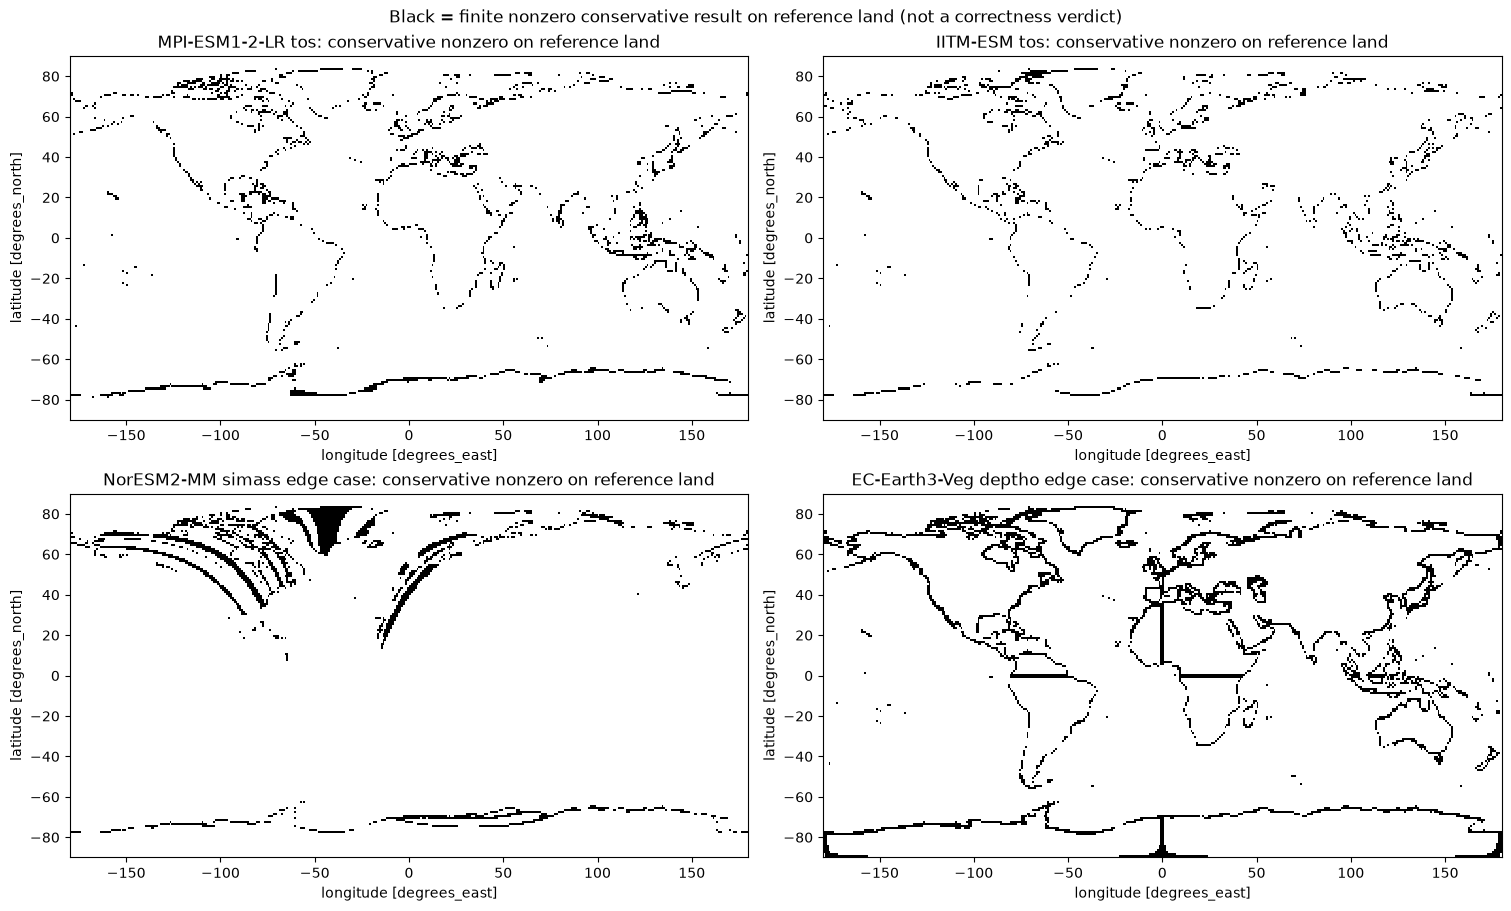

,case,comparison,units,common_valid,finite_mask_disagreements,mean_absolute_difference,rmse,max_absolute_difference
0,MPI-ESM1-2-LR tos,nearest_s2d - bilinear,degC,40502,2177,0.134701,0.227673,3.740678
1,MPI-ESM1-2-LR tos,nearest_s2d - conservative,degC,42586,227,0.119465,0.216230,3.820607
2,MPI-ESM1-2-LR tos,nearest_s2d - patch,degC,42548,299,0.136391,0.229931,3.814614
3,MPI-ESM1-2-LR tos,bilinear - conservative,degC,40502,2218,0.035175,0.071588,2.680727
4,MPI-ESM1-2-LR tos,bilinear - patch,degC,40502,2214,0.011285,0.023490,0.737225
5,MPI-ESM1-2-LR tos,conservative - patch,degC,42627,182,0.038391,0.075241,2.278359
6,IITM-ESM tos,nearest_s2d - bilinear,degC,40675,1645,0.018035,0.045734,0.803305
7,IITM-ESM tos,nearest_s2d - conservative,degC,41566,782,0.021036,0.050843,0.963934
8,IITM-ESM tos,nearest_s2d - patch,degC,42265,90,0.032837,0.058383,0.836411
9,IITM-ESM tos,bilinear - conservative,degC,40398,1473,0.003638,0.009260,0.348127


In [9]:
mask_1deg_path = ocean_cache / 'land_sea_mask_1degree.nc4'
mask_1deg_url = 'https://raw.githubusercontent.com/roocs/roocs-grids/main/roocs_grids/grids/land_sea_mask_1degree.nc4'
if not mask_1deg_path.exists():
    mask_download = requests.get(mask_1deg_url, timeout=60)
    mask_download.raise_for_status()
    mask_1deg_path.write_bytes(mask_download.content)
with xr.open_dataset(mask_1deg_path) as dataset:
    reference_fraction_1deg = dataset.sftlf.load()
if not bool(np.isfinite(reference_fraction_1deg).all()) or float(reference_fraction_1deg.min()) < 0 or float(reference_fraction_1deg.max()) > 1:
    raise ValueError('Expected finite fractional land mask in [0, 1]')
print('Reference coastline:', mask_1deg_url, 'sha256:', sha256(mask_1deg_path.read_bytes()).hexdigest())

def canonical_edge_grid(field):
    return field.assign_coords(lon=((field.lon + 180) % 360) - 180).sortby('lon').sortby('lat')

edge_land_rows = []
figure, axes = plt.subplots(2, 2, figsize=(15, 9), constrained_layout=True)
for axis, (case_name, case) in zip(axes.flat, ocean_cases.items()):
    for method, result in case['results'].items():
        field = result[case['variable']]
        if 'time' in field.dims:
            field = field.isel(time=0)
        field, fraction = xr.align(canonical_edge_grid(field), canonical_edge_grid(reference_fraction_1deg), join='exact')
        reference_land = fraction >= 0.5
        finite_on_land = np.isfinite(field) & reference_land
        edge_land_rows.append({
            'case': case_name, 'method': method,
            'finite_reference_land': int(finite_on_land.sum().item()),
            'nonzero_reference_land': int((finite_on_land & (field != 0)).sum().item()),
            'missing_reference_ocean': int(((~np.isfinite(field)) & (~reference_land)).sum().item()),
        })
        if method == 'conservative':
            (finite_on_land & (field != 0)).astype(int).plot(ax=axis, vmin=0, vmax=1, cmap='Greys', add_colorbar=False)
            axis.set_title(f'{case_name}: conservative nonzero on reference land')
display(pd.DataFrame(edge_land_rows))
figure.suptitle('Black = finite nonzero conservative result on reference land (not a correctness verdict)')
plt.show()

edge_pair_rows = []
for case_name, case in ocean_cases.items():
    for method_a, method_b in combinations(case['results'], 2):
        field_a, field_b = xr.align(case['results'][method_a][case['variable']],
                                   case['results'][method_b][case['variable']], join='exact')
        finite_a, finite_b = np.isfinite(field_a), np.isfinite(field_b)
        common = finite_a & finite_b
        if int(common.sum().item()) == 0:
            raise ValueError(f'{case_name}: no common valid values for {method_a}/{method_b}')
        difference = (field_a - field_b).where(common)
        edge_pair_rows.append({
            'case': case_name, 'comparison': f'{method_a} - {method_b}',
            'units': field_a.attrs.get('units'),
            'common_valid': int(common.sum().item()),
            'finite_mask_disagreements': int((finite_a != finite_b).sum().item()),
            'mean_absolute_difference': float(abs(difference).mean(skipna=True).item()),
            'rmse': float(np.sqrt((difference**2).mean(skipna=True)).item()),
            'max_absolute_difference': float(abs(difference).max(skipna=True).item()),
        })
display(pd.DataFrame(edge_pair_rows))


### PDF edge-case findings (2026-11-13, rooki Conda kernel)

**The documented conservative-remapping artifact patterns remain visible in these tests.** All six new nearest/bilinear/conservative requests completed, with the expected 1-degree coordinates, unchanged units, no infinities, no negative values, and no departures from the native value range. Those checks alone would therefore miss the spatial problems shown in the maps.

| Case | Native-grid evidence | Regridded observations |
| --- | --- | --- |
| NorESM2-MM `simass`, D.2.1.10 Figure 2 | 39,852 non-finite coordinate pairs; 39,672 cells with fewer than three unique finite vertices; 1,880 cells with latitude span >50 degrees | The conservative map shows broad streaks across land resembling the report's artifact pattern. Nearest-versus-conservative RMSE on common valid cells is 406.87 kg m-2; mask patterns disagree in 2,586 cells. |
| EC-Earth3-Veg `deptho`, Figure 3 | 834 cells with fewer than three unique finite vertices and 1,408 duplicate centres | Conservative output shows strong meridional/equatorial and block-like features. Nearest-versus-conservative RMSE on common valid cells is 779.07 m; mask patterns disagree in 4,383 cells. Native depth is zero in many land cells, so finite coverage alone is not leakage evidence. |
| MPI-ESM1-2-LR `tos`, halo example | 440 duplicate centres and 25 cells with fewer than three unique finite vertices | This supports the presence of problematic geometry, but does not test halo removal or adaptive-masking toggles; the service exposes neither control. |
| IITM-ESM `tos`, Figure 4 / related longitude-frame issue | Native longitudes span -279.980316 to 79.980324 degrees; no CF-linked bounds were delivered | The earlier remapping completes on a standard target grid despite this source longitude frame. It is not the exact unavailable `thetao` 1pctCO2 example. |

The reference-land diagnostic finds **2,525 nonzero conservative `simass` cells** on reference land versus **1,098 for nearest** (bilinear: 573). This is consistent with the visibly extensive streaks, while individual coastal differences may reflect mask/model coastline mismatch. The corresponding `deptho` counts are 4,566 conservative, 2,532 nearest and 7,611 bilinear; counts alone cannot rank scientific accuracy. No mask was applied to the remote requests in this section.

The NorESM2 `patch` attempt remains **incomplete** after waiting more than 13 minutes; local execution was stopped, not the remote job. It is excluded from these comparisons and will not be automatically resubmitted. The unavailable-dataset and unstructured-grid gaps listed above remain **untested**, not passes. These single-slice diagnostics reproduce warning signs; they do not establish conservation, a generally best method, or complete validation of either deliverable.